# Visual check: raters vs raters vs model (standalone, T2 only)
Shows, per slice: image | r1 | r2 | r3 | where the raters agree/disagree | model prediction. Reads the checkpoint (and `splits-2.csv`, optional) from the `new results` folder on Google Drive. No training is run.

In [ ]:
!pip -q install nibabel

In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Mounted at /content/drive


## Definitions (config, data loader, model, loss/metrics)

In [ ]:
"""
Central configuration for the cross-site generalization study.

Actual UT-EndoMRI layout (per the dataset README):

    DATA_ROOT/
        D1_MHS/
            D1-000/
                D1-000_T1.nii.gz
                D1-000_T1FS.nii.gz
                D1-000_T2.nii.gz
                D1-000_T2FS.nii.gz
                D1-000_ut_r1.nii.gz      <- uterus, rater 1
                D1-000_ut_r2.nii.gz      <- uterus, rater 2 (if present)
                D1-000_ov_r1.nii.gz      <- ovary, rater 1
                D1-000_em_r1.nii.gz      <- endometrioma, rater 1
                ...
            D1-001/
                ...
        D2_TCPW/
            D2-006/
                D2-006_T2.nii.gz
                D2-006_ut.nii.gz         <- single rater, no _r suffix
                D2-006_ov.nii.gz
                ...

Not every patient has every MRI sequence or every structure label
(sequences may be missing due to acquisition; some structures may not
have been contoured for a given patient).
"""

import os

# ---- Paths -------------------------------------------------------------
DATA_ROOT = "/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI"  # <-- EDIT ME

SITE_A_NAME = "D1_MHS"    # training / in-distribution site
SITE_B_NAME = "D2_TCPW"   # external / out-of-distribution site

SITE_A_DIR = os.path.join(DATA_ROOT, SITE_A_NAME)
SITE_B_DIR = os.path.join(DATA_ROOT, SITE_B_NAME)

OUTPUT_DIR = "/content/outputs"   # checkpoints, csvs, plots all go here
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "unet_site_a.pt")

# ---- MRI sequence selection ----------------------------------------------
# T2 ONLY, for both sites. D1 has no T2FS and D2 has T2 as well, so using
# plain T2 everywhere keeps image contrast matched across sites. There is
# deliberately NO fallback sequence: patients without a T2 image are
# excluded, so no site can silently get a different contrast.
MRI_SEQUENCE_PRIORITY = ["T2"]

# ---- Structures / labels ---------------------------------------------------
# Maps the dataset's structure abbreviation -> the integer class id to use
# in the combined multi-class mask. 0 = background is implicit; do not use
# 0 here. Order matters when structures overlap in space: later entries
# are drawn ON TOP of earlier ones (see data.load_combined_mask).
STRUCTURES_OF_INTEREST = {
    "ut": 1,   # uterus
    "ov": 2,   # ovary
    "em": 3,   # endometrioma
}
LABEL_MAP = {0: "background"}
for abbrev, class_id in STRUCTURES_OF_INTEREST.items():
    LABEL_MAP[class_id] = {"ut": "uterus", "ov": "ovaries", "em": "endometrioma",
                            "cy": "cyst", "cds": "cul_de_sac"}.get(abbrev, abbrev)
NUM_CLASSES = len(LABEL_MAP)

# When a structure has multiple raters (D1_MHS only), prefer this rater ID
# if available, otherwise fall back to whichever rater's file exists.
PREFERRED_RATER = "r1"

# If a patient is missing a label file for one of STRUCTURES_OF_INTEREST
# entirely, I still include them rather than dropping
# the whole case. absence-of-file != confirmed absence of the structure in the scan.
REQUIRE_ALL_STRUCTURES = False

# ---- Data / preprocessing ------------------------------------------------
IMAGE_SIZE = 256
SLICE_AXIS = 2              # axial slicing; 0/1/2 = sagittal/coronal/axial
                             # (depends on how volumes are oriented — check!)
MIN_FOREGROUND_PIXELS = 10  # skip slices with fewer than this many
                             # foreground pixels (mostly-empty slices)

# train/val split done WITHIN site A only (site B is never used for
# training or model selection — it's held out entirely for the
# generalization test)
VAL_FRACTION = 0.2
RANDOM_SEED = 42

# ---- Training --------------------------------------------------------------
BATCH_SIZE = 8
NUM_EPOCHS = 40
LEARNING_RATE = 1e-3
BASE_CHANNELS = 32
DEVICE = "cuda"
NUM_WORKERS = 2

In [ ]:
import os
import glob
import numpy as np
import nibabel as nib
from nibabel.processing import resample_from_to
import torch
from torch.utils.data import Dataset
from skimage.transform import resize


def find_image_path(patient_dir, patient_id):
    """Pick the first available MRI sequence for this patient, in
    MRI_SEQUENCE_PRIORITY order. Returns (path, sequence_name) or
    (None, None) if no listed sequence is present. If nothing matches,
    prints what files actually exist in the folder."""
    for seq in MRI_SEQUENCE_PRIORITY:
        candidate = os.path.join(patient_dir, f"{patient_id}_{seq}.nii.gz")
        if os.path.exists(candidate):
            return candidate, seq

    existing = sorted(os.path.basename(p) for p in
                       glob.glob(os.path.join(patient_dir, "*.nii.gz")))
    print(f"[warn] {patient_id}: none of "
          f"{ [f'{patient_id}_{s}.nii.gz' for s in MRI_SEQUENCE_PRIORITY]} "
          f"found. Files actually present: {existing}")
    return None, None


def find_structure_label_path(patient_dir, patient_id, structure):
    """
    Find the label file for one structure abbreviation (e.g. 'ut').

    Handles both naming conventions:
      - D1_MHS (multi-rater): {patient_id}_{structure}_r{rater}.nii.gz
      - D2_TCPW (single rater): {patient_id}_{structure}.nii.gz

    Prefers PREFERRED_RATER if multiple raters exist, otherwise
    falls back to whichever rater's file is found first
    """
    # single-rater / no-rater-suffix convention (D2_TCPW)
    plain_path = os.path.join(patient_dir, f"{patient_id}_{structure}.nii.gz")
    if os.path.exists(plain_path):
        return plain_path

    # multi-rater convention (D1_MHS)
    rater_pattern = os.path.join(patient_dir, f"{patient_id}_{structure}_r*.nii.gz")
    rater_files = sorted(glob.glob(rater_pattern))
    if not rater_files:
        return None

    preferred = os.path.join(patient_dir,
                              f"{patient_id}_{structure}_{PREFERRED_RATER}.nii.gz")
    if preferred in rater_files:
        return preferred
    return rater_files[0]  # fall back to first available rater


def discover_cases(site_dir):
    """
    Walk a site directory and build a list of case records:
        {
            "case_id": "D1-000",
            "site_dir": <path>,
            "image_path": <path>,
            "sequence": "T2FS",
            "label_paths": {"ut": <path or None>, "ov": <path or None>},
        }
    """
    patient_dirs = sorted(
        d for d in glob.glob(os.path.join(site_dir, "*")) if os.path.isdir(d)
    )
    if not patient_dirs:
        raise FileNotFoundError(
            f"No patient subfolders found under {site_dir}. "
            f"Check DATA_ROOT / site folder names."
        )

    cases = []
    for patient_dir in patient_dirs:
        patient_id = os.path.basename(patient_dir.rstrip("/"))

        image_path, sequence = find_image_path(patient_dir, patient_id)
        if image_path is None:
            print(f"[warn] {patient_id}: skipping patient (no usable sequence)")
            continue

        label_paths = {}
        for structure in STRUCTURES_OF_INTEREST:
            label_paths[structure] = find_structure_label_path(
                patient_dir, patient_id, structure
            )

        missing = [s for s, p in label_paths.items() if p is None]
        if missing:
            msg = f"[warn] {patient_id}: missing label(s) for {missing}"
            if REQUIRE_ALL_STRUCTURES:
                print(msg + " -> skipping patient (REQUIRE_ALL_STRUCTURES=True)")
                continue
            else:
                print(msg + " -> treating as background for that structure")

        if all(p is None for p in label_paths.values()):
            print(f"[warn] {patient_id}: no structure labels found at all, "
                  f"skipping patient")
            continue

        cases.append({
            "case_id": patient_id,
            "site_dir": site_dir,
            "image_path": image_path,
            "sequence": sequence,
            "label_paths": label_paths,
        })

    print(f"[data] {os.path.basename(site_dir)}: {len(cases)} usable "
          f"patients out of {len(patient_dirs)} folders found")
    return cases


def load_combined_mask(image_nii, label_paths):
    """
    Build a single multi-class mask array,from the per-structure label files for one case.

    Missing structures (None path) contribute nothing (stay
    background).
    """
    image_shape = image_nii.shape
    mask = np.zeros(image_shape, dtype=np.int64)

    for structure, class_id in STRUCTURES_OF_INTEREST.items():
        path = label_paths.get(structure)
        if path is None:
            continue

        label_nii = nib.load(path)

        same_grid = (label_nii.shape == image_shape and
                     np.allclose(label_nii.affine, image_nii.affine, atol=1e-3))

        if same_grid:
            vol = label_nii.get_fdata()
        else:
            try:
                # order=0 = nearest-neighbor, required for label data
                # (linear/cubic interpolation would invent fractional
                # class values between e.g. 0 and 1)
                resampled_nii = resample_from_to(label_nii, image_nii, order=0)
                vol = resampled_nii.get_fdata()
            except Exception as e:
                print(f"[warn] could not resample {path} onto the image "
                      f"grid ({label_nii.shape} -> {image_shape}): {e}. "
                      f"Skipping this structure for this case.")
                continue

        mask[vol > 0.5] = class_id

    return mask


def normalize_intensity(slice_2d):
    """Percentile-clip then min-max normalize a single MRI slice to [0, 1]."""
    p1, p99 = np.percentile(slice_2d, (1, 99))
    slice_2d = np.clip(slice_2d, p1, p99)
    denom = (p99 - p1) if (p99 - p1) > 1e-6 else 1.0
    return (slice_2d - p1) / denom


def extract_slices(case, site_name):
    """Load one case's volume + combined mask, return per-slice records.
    """
    image_nii = nib.load(case["image_path"])
    image_nii = nib.as_closest_canonical(image_nii)
    img_vol = image_nii.get_fdata().astype(np.float32)
    mask_vol = load_combined_mask(image_nii, case["label_paths"])

    n_slices = img_vol.shape[SLICE_AXIS]
    records = []
    for i in range(n_slices):
        img_slice = np.take(img_vol, i, axis=SLICE_AXIS)
        mask_slice = np.take(mask_vol, i, axis=SLICE_AXIS)

        if np.count_nonzero(mask_slice) < MIN_FOREGROUND_PIXELS:
            continue  # skip near-empty slices

        records.append({
            "case_id": case["case_id"],
            "site": site_name,
            "slice_idx": i,
            "image": img_slice,
            "mask": mask_slice,
        })
    return records


class EndoMRISliceDataset(Dataset):
    """
    2D slice dataset built from a list of case records (see discover_cases).

    Each item returns:
        image: FloatTensor [1, H, W], normalized to [0, 1]
        mask:  LongTensor  [H, W], integer class labels
        meta:  dict with case_id, site, slice_idx (for later analysis)
    """

    def __init__(self, cases, site_name, augment=False):
        self.site_name = site_name
        self.augment = augment
        self.records = []
        for case in cases:
            self.records.extend(extract_slices(case, site_name))
        print(f"[data] {site_name}: {len(cases)} cases -> "
              f"{len(self.records)} usable slices")

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = normalize_intensity(rec["image"])
        mask = rec["mask"]

        img = resize(img, (IMAGE_SIZE, IMAGE_SIZE),
                     order=1, preserve_range=True, anti_aliasing=True)
        mask = resize(mask, (IMAGE_SIZE, IMAGE_SIZE),
                      order=0, preserve_range=True, anti_aliasing=False)

        if self.augment and np.random.rand() < 0.5:
            img = np.fliplr(img).copy()
            mask = np.fliplr(mask).copy()

        image_t = torch.from_numpy(img).float().unsqueeze(0)
        mask_t = torch.from_numpy(mask).long()

        meta = {
            "case_id": rec["case_id"],
            "site": rec["site"],
            "slice_idx": rec["slice_idx"],
        }
        return image_t, mask_t, meta


def split_cases_train_val(cases, val_fraction, seed):
    """Split at the case lvl to avoid leaking slices
    from the same patient across train/val."""
    rng = np.random.RandomState(seed)
    idx = np.arange(len(cases))
    rng.shuffle(idx)
    n_val = max(1, int(len(idx) * val_fraction))
    val_idx = set(idx[:n_val])
    train_cases = [c for i, c in enumerate(cases) if i not in val_idx]
    val_cases = [c for i, c in enumerate(cases) if i in val_idx]
    return train_cases, val_cases


In [ ]:
"""
INTER-RATER AGREEMENT WITH THE SAME 2D PROTOCOL AS THE MODEL RESULTS
"""
import os
import re
import glob
import itertools
import numpy as np
import pandas as pd
import nibabel as nib
from skimage.transform import resize

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
FOLDER_NAME = "new results"          # outputs go to <folder>/rater_agreement_2d
# -------------------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")


def find_folder(root, name, max_depth=3):
    root = root.rstrip("/")
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
            continue
        for d in dirnames:
            if d.lower() == name.lower():
                return os.path.join(dirpath, d)
    return None


PROJECT_DIR = os.path.join(DRIVE_ROOT, FOLDER_NAME)
if not os.path.isdir(PROJECT_DIR):
    PROJECT_DIR = find_folder(DRIVE_ROOT, FOLDER_NAME)
if PROJECT_DIR is None:
    raise FileNotFoundError(f"No folder named '{FOLDER_NAME}' found under {DRIVE_ROOT}.")
OUT_DIR = os.path.join(PROJECT_DIR, "rater_agreement_2d")
os.makedirs(OUT_DIR, exist_ok=True)

CLASS_IDS = list(range(1, NUM_CLASSES))
_RATER_RE = re.compile(r"_(?P<st>[a-z]+)_(?P<rater>r\d+)\.nii\.gz$")
EMPTY_FILES = set()


def case_rater_files(case):
    pdir = os.path.join(case["site_dir"], case["case_id"])
    out = {}
    for st in STRUCTURES_OF_INTEREST:
        for p in glob.glob(os.path.join(pdir, f"{case['case_id']}_{st}_r*.nii.gz")):
            m = _RATER_RE.search(os.path.basename(p))
            if m and m.group("st") == st:
                out.setdefault(m.group("rater"), {})[st] = p
    return out


def rater_label_paths(rf, rater):
    return {st: rf.get(rater, {}).get(st) for st in STRUCTURES_OF_INTEREST}


def audit_empty(files_all):
    EMPTY_FILES.clear()
    for cid, per in files_all.items():
        for r, sts in per.items():
            for st, p in sts.items():
                if not np.asarray(nib.load(p).dataobj).any():
                    EMPTY_FILES.add((cid, r, st))
    print(f"label files that exist but are empty: {len(EMPTY_FILES)}")


def participates(cid, files, rater, organ):
    if rater not in files:
        return False
    if organ == "uterus":
        return "ut" in files[rater] and (cid, rater, "ut") not in EMPTY_FILES
    return True


def dice_class(a, b):
    d = a.sum() + b.sum()
    return np.nan if d == 0 else 2.0 * np.logical_and(a, b).sum() / d


def one_direction(ref_native, oth_native):
    """Reference rater defines the slices; 'other' plays the prediction. Returns {class_id: mean over slices}."""
    n = ref_native.shape[SLICE_AXIS]
    per_class = {c: [] for c in CLASS_IDS}
    for i in range(n):
        r = np.take(ref_native, i, axis=SLICE_AXIS)
        if np.count_nonzero(r) < MIN_FOREGROUND_PIXELS:                  # same slice rule as the model evaluation
            continue
        o = np.take(oth_native, i, axis=SLICE_AXIS)
        rr = resize(r, (IMAGE_SIZE, IMAGE_SIZE), order=0, preserve_range=True, anti_aliasing=False)
        oo = resize(o, (IMAGE_SIZE, IMAGE_SIZE), order=0, preserve_range=True, anti_aliasing=False)
        for c in CLASS_IDS:
            per_class[c].append(dice_class(oo == c, rr == c))
    out = {}
    for c, v in per_class.items():
        v = np.asarray(v, float)
        out[c] = np.nan if v.size == 0 or np.all(np.isnan(v)) else float(np.nanmean(v))
    return out


def run_2d_agreement():
    cases = discover_cases(SITE_A_DIR)
    files_all = {c["case_id"]: case_rater_files(c) for c in cases}
    audit_empty(files_all)
    rows = []
    for c in cases:
        cid, files = c["case_id"], files_all[c["case_id"]]
        if len(files) < 2:
            continue
        image_nii = nib.as_closest_canonical(nib.load(c["image_path"]))
        masks = {r: load_combined_mask(image_nii, rater_label_paths(files, r)) for r in files}
        for ra, rb in itertools.combinations(sorted(files), 2):
            ab, ba = one_direction(masks[ra], masks[rb]), one_direction(masks[rb], masks[ra])
            for cls in CLASS_IDS:
                organ = LABEL_MAP[cls]
                if not (participates(cid, files, ra, organ) and participates(cid, files, rb, organ)):
                    continue
                v = np.nanmean([ab[cls], ba[cls]]) if not (np.isnan(ab[cls]) and np.isnan(ba[cls])) else np.nan
                rows.append({"case_id": cid, "organ": organ, "pair": f"{ra}-{rb}", "dice_2d": v,
                             f"{ra}_as_reference": ab[cls], f"{rb}_as_reference": ba[cls]})
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(OUT_DIR, "pairwise_dice_2d.csv"), index=False)
    g = df.dropna(subset=["dice_2d"]).groupby(["organ", "pair"])["dice_2d"].agg(["mean", "std", "median", "count"])
    g.columns = ["mean 2D Dice", "std", "median", "n patients"]
    out = g.round(3)

    p3d = None
    hits = sorted(glob.glob(os.path.join(DRIVE_ROOT, "**", "pairwise_dice.csv"), recursive=True), key=os.path.getmtime, reverse=True)
    if hits:
        p3d = pd.read_csv(hits[0]).dropna(subset=["dice"]).groupby(["organ", "pair"])["dice"].mean().round(3)
        out = out.join(p3d.rename("mean 3D Dice (earlier table)"))
    pd.set_option("display.width", 200)
    print("\n=== Pairwise rater agreement, 2D protocol of the model results (both directions averaged) ===")
    print(out.to_string())
    allp = df.dropna(subset=["dice_2d"]).groupby("organ")["dice_2d"].agg(["mean", "count"]).round(3)
    print("\n=== Mean over all rater pairs, per organ (2D protocol) ===")
    print(allp.to_string())
    out.to_csv(os.path.join(OUT_DIR, "table_pairwise_dice_2d.csv"))
    print("\nsaved to:", OUT_DIR)
    return df, out


df_rater_2d, table_rater_2d = run_2d_agreement()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none of ['D1-014_T2.nii.gz'] found. Files actually present: ['D1-014_T1FS.nii.gz', 'D1-014_em_r3.nii.gz', 'D1-014_ut_r3.nii.gz']
[warn] D1-014: skippi

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none of ['D1-014_T2.nii.gz'] found. Files actually present: ['D1-014_T1FS.nii.gz', 'D1-014_em_r3.nii.gz', 'D1-014_ut_r3.nii.gz']
[warn] D1-014: skippi

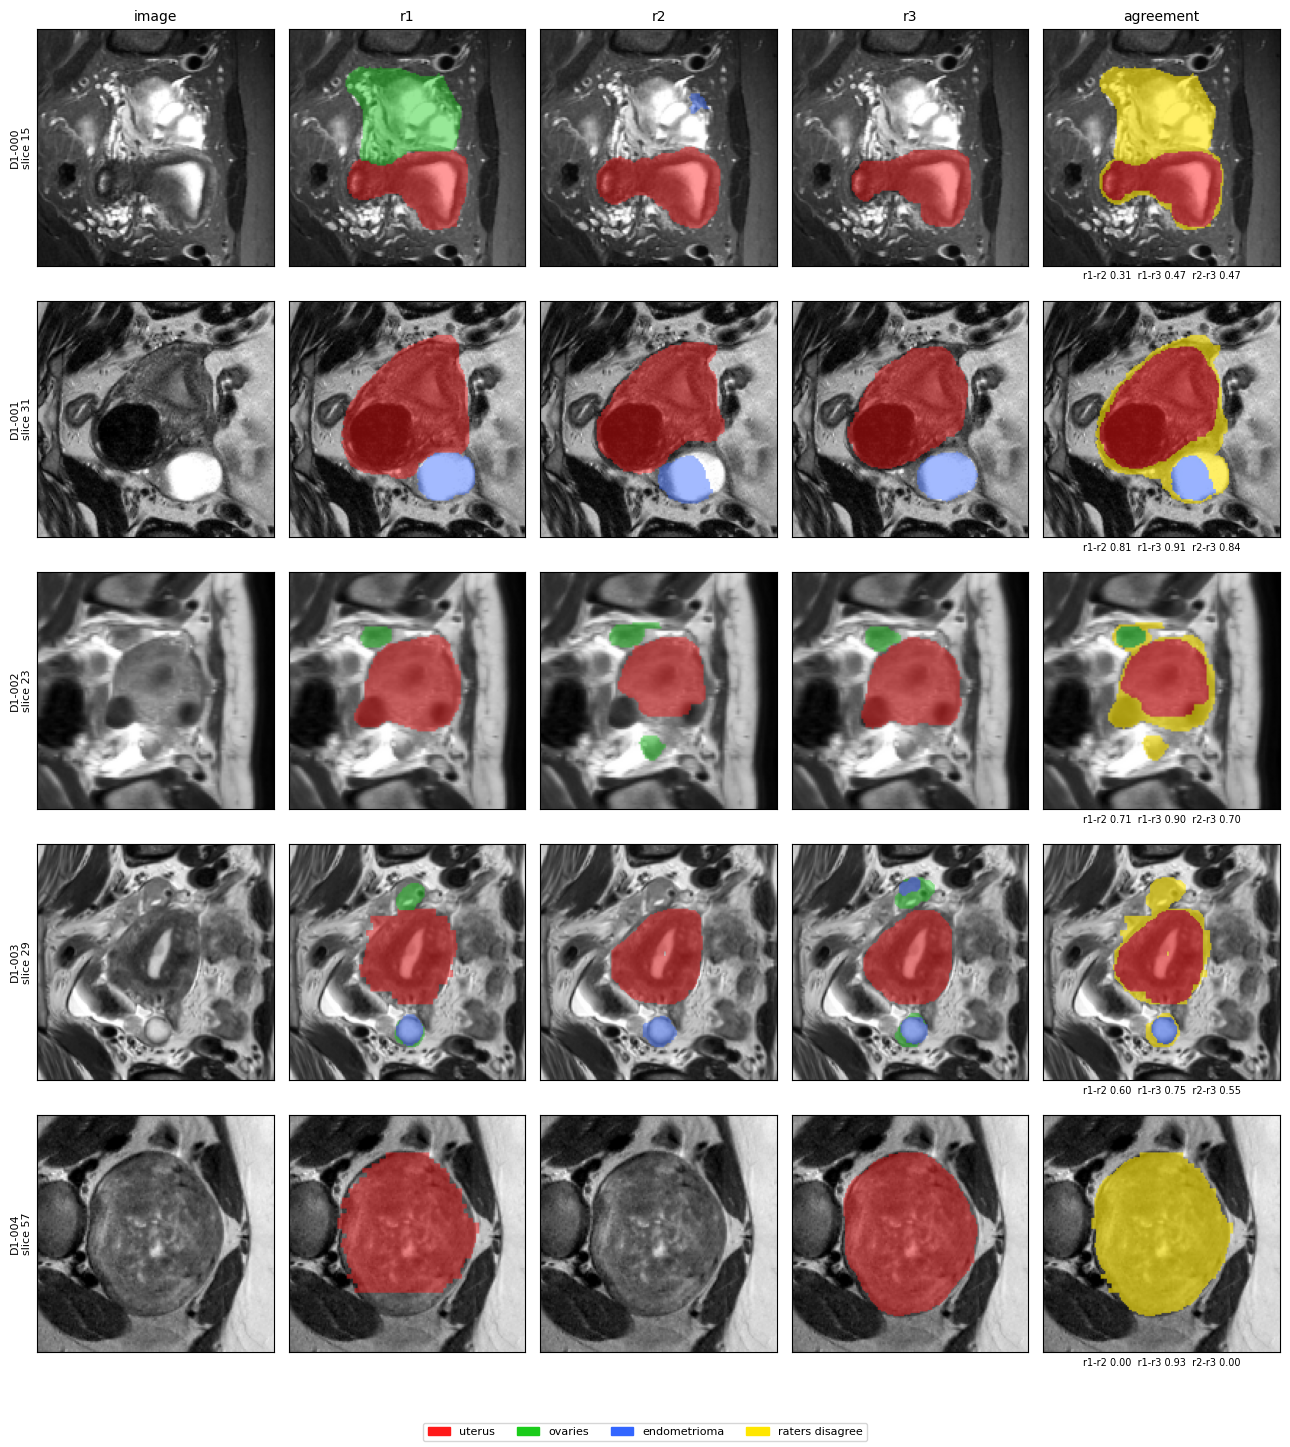

saved /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/rater_comparison_complete/complete_patients_overlays_1.png


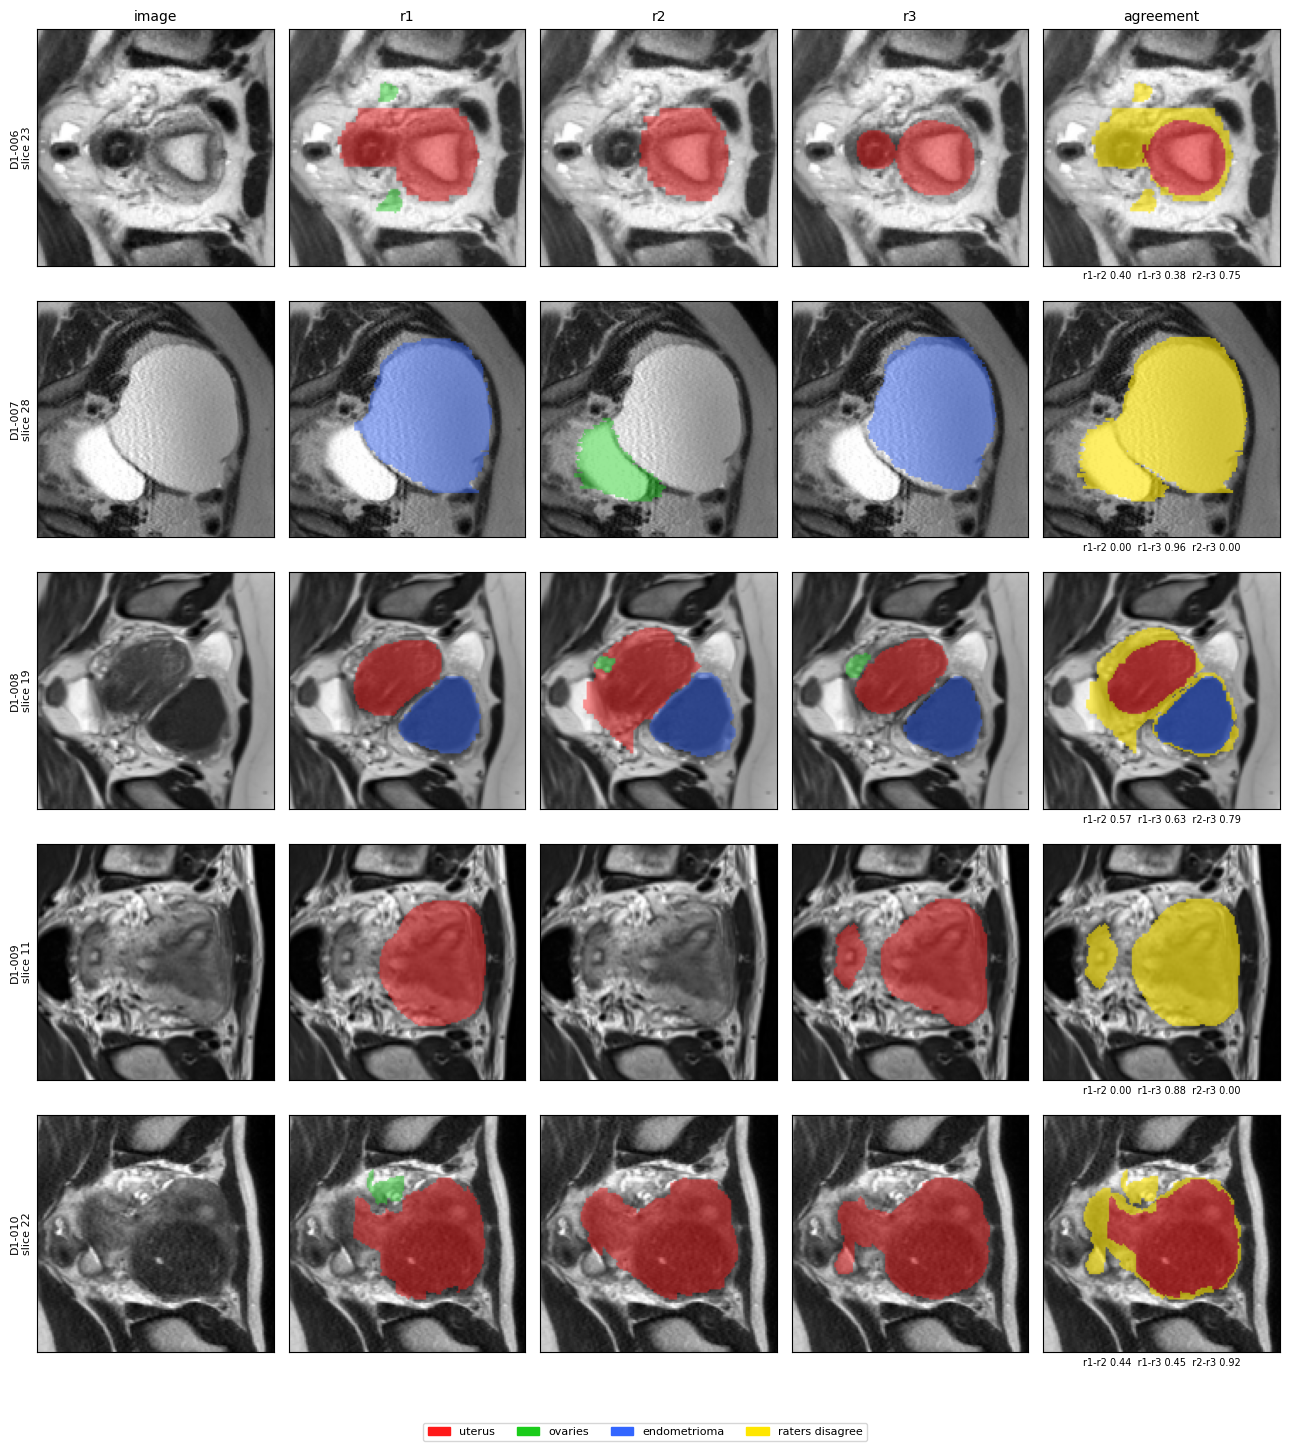

saved /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/rater_comparison_complete/complete_patients_overlays_2.png


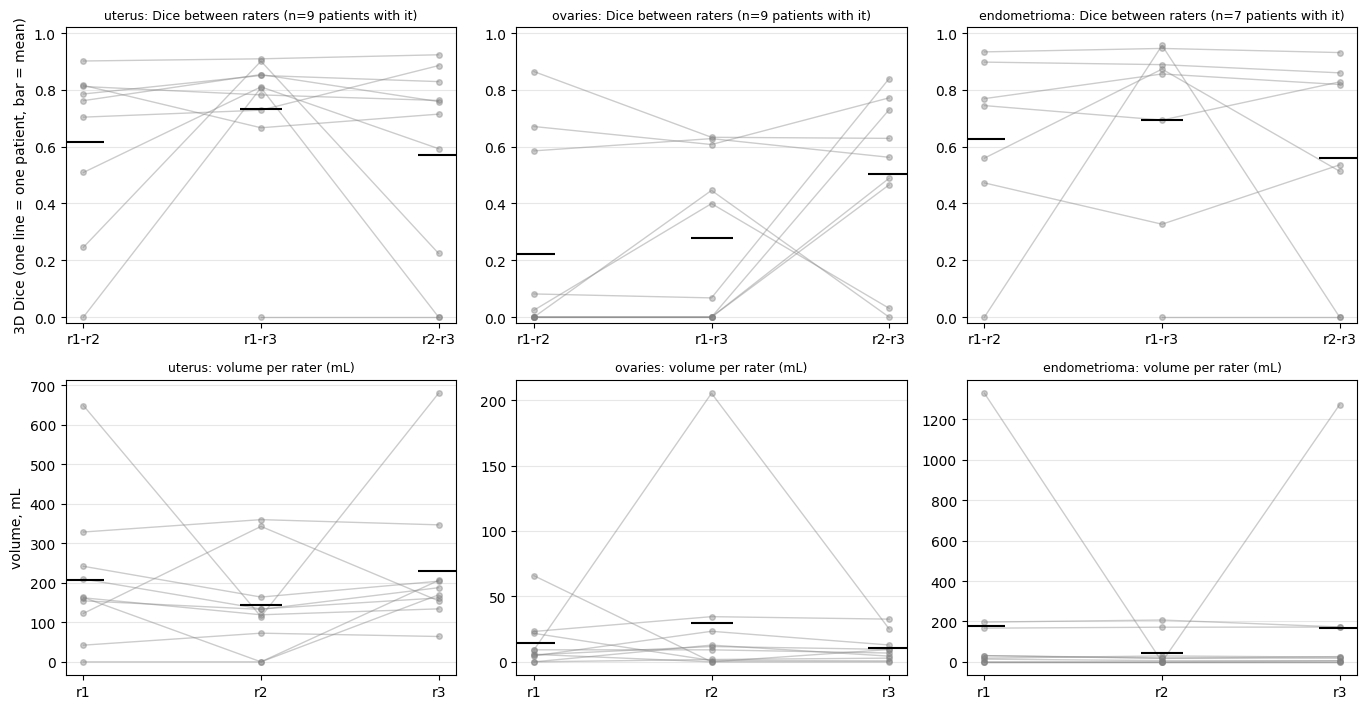

saved /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/rater_comparison_complete/complete_patients_summary.png

=== Mean 3D Dice between raters, patients annotated by all raters ===
                     mean    std  count
organ        pair                      
endometrioma r1-r2  0.625  0.322      7
             r1-r3  0.692  0.347      8
             r2-r3  0.561  0.377      8
ovaries      r1-r2  0.223  0.342     10
             r1-r3  0.278  0.289     10
             r2-r3  0.502  0.303      9
uterus       r1-r2  0.615  0.305      9
             r1-r3  0.731  0.267     10
             r2-r3  0.569  0.358     10

=== Mean volume (mL) per rater ===
rater            r1     r2     r3
organ                            
endometrioma  178.6   45.0  169.5
ovaries        14.5   30.0   10.4
uterus        207.3  143.9  230.8

=== Patients where the raters disagree MOST on the uterus (mean pairwise Dice) ===
case_id
D1-007    0.000
D1-009    0.269
D1-004    0.457
D1-008    0.637


In [ ]:
"""
Rater comparison on the patients annotated by all raters
"""
import os
import re
import glob
import itertools
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from skimage.transform import resize

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
FOLDER_NAME = "new results"          # outputs are saved to <folder>/rater_comparison_complete
ROWS_PER_FIGURE = 5
ZOOM = True
ZOOM_MARGIN = 24
# -------------------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")


def find_folder(root, name, max_depth=3):
    root = root.rstrip("/")
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
            continue
        for d in dirnames:
            if d.lower() == name.lower():
                return os.path.join(dirpath, d)
    return None


PROJECT_DIR = os.path.join(DRIVE_ROOT, FOLDER_NAME)
if not os.path.isdir(PROJECT_DIR):
    PROJECT_DIR = find_folder(DRIVE_ROOT, FOLDER_NAME)
if PROJECT_DIR is None:
    raise FileNotFoundError(f"No folder named '{FOLDER_NAME}' found under {DRIVE_ROOT}.")
OUT_DIR = os.path.join(PROJECT_DIR, "rater_comparison_complete")
os.makedirs(OUT_DIR, exist_ok=True)

CLASS_IDS = list(range(1, NUM_CLASSES))
ORGANS = [LABEL_MAP[c] for c in CLASS_IDS]
CLASS_COLORS = {1: (1.0, 0.1, 0.1), 2: (0.1, 0.8, 0.1), 3: (0.2, 0.4, 1.0)}
_RATER_RE = re.compile(r"_(?P<st>[a-z]+)_(?P<rater>r\d+)\.nii\.gz$")


# ------------------------------------------------------------ rater files
def case_rater_files(case):
    pdir = os.path.join(case["site_dir"], case["case_id"])
    out = {}
    for st in STRUCTURES_OF_INTEREST:
        for p in glob.glob(os.path.join(pdir, f"{case['case_id']}_{st}_r*.nii.gz")):
            m = _RATER_RE.search(os.path.basename(p))
            if m and m.group("st") == st:
                out.setdefault(m.group("rater"), {})[st] = p
    return out


def rater_label_paths(rater_files, rater):
    return {st: rater_files.get(rater, {}).get(st) for st in STRUCTURES_OF_INTEREST}


# ---------------------------------------------------------------- helpers
def volumetric_dice(a, b):
    denom = a.sum() + b.sum()
    return np.nan if denom == 0 else 2.0 * np.logical_and(a, b).sum() / denom


def slice_dice(a, b):
    vals = [volumetric_dice(a == c, b == c) for c in CLASS_IDS]
    return np.nan if np.all(np.isnan(vals)) else float(np.nanmean(vals))


def fmt(x):
    return "n/a" if x is None or np.isnan(x) else f"{x:.2f}"


def prep_image_slice(img_vol, i):
    s = normalize_intensity(np.take(img_vol, i, axis=SLICE_AXIS))
    return resize(s, (IMAGE_SIZE, IMAGE_SIZE), order=1, preserve_range=True,
                  anti_aliasing=True).astype(np.float32)


def prep_mask_slice(mask_vol, i):
    return resize(np.take(mask_vol, i, axis=SLICE_AXIS), (IMAGE_SIZE, IMAGE_SIZE),
                  order=0, preserve_range=True, anti_aliasing=False).astype(np.int8)


def overlay(img, mask, alpha=0.45):
    rgb = np.stack([img] * 3, axis=-1).astype(np.float32)
    for c, col in CLASS_COLORS.items():
        m = mask == c
        if m.any():
            rgb[m] = (1 - alpha) * rgb[m] + alpha * np.array(col)
    return np.clip(rgb, 0, 1)


def agreement_overlay(img, masks, alpha=0.5):
    stack = np.stack(masks)
    same = (stack == stack[0]).all(axis=0)
    rgb = overlay(img, np.where(same & (stack[0] > 0), stack[0], 0), alpha)
    rgb[~same] = 0.4 * rgb[~same] + 0.6 * np.array((1.0, 0.9, 0.0))
    return np.clip(rgb, 0, 1)


def zoom_box(masks, margin):
    fg = np.any(np.stack(masks) > 0, axis=0)
    if not fg.any():
        return slice(0, IMAGE_SIZE), slice(0, IMAGE_SIZE)
    rows, cols = np.where(fg)
    r0, r1, c0, c1 = rows.min() - margin, rows.max() + margin, cols.min() - margin, cols.max() + margin
    side = max(r1 - r0, c1 - c0)
    cr, cc = (r0 + r1) // 2, (c0 + c1) // 2
    r0, c0 = max(0, cr - side // 2), max(0, cc - side // 2)
    return slice(r0, min(IMAGE_SIZE, r0 + side)), slice(c0, min(IMAGE_SIZE, c0 + side))


# ------------------------------------------------------------------- run
def run_complete_patient_comparison():
    cases = discover_cases(SITE_A_DIR)
    files = {c["case_id"]: case_rater_files(c) for c in cases}
    raters = sorted({r for f in files.values() for r in f})
    complete = [c for c in cases if all(r in files[c["case_id"]] for r in raters)]
    print(f"raters: {raters}; patients annotated by ALL of them: {len(complete)} of {len(cases)}")
    if not complete:
        raise RuntimeError("No patient is annotated by all raters.")

    rows, pair_rows, vol_rows = [], [], []
    for c in complete:
        cid = c["case_id"]
        image_nii = nib.as_closest_canonical(nib.load(c["image_path"]))
        img_vol = image_nii.get_fdata().astype(np.float32)
        vox_ml = float(np.prod(np.sqrt((image_nii.affine[:3, :3] ** 2).sum(0)))) / 1000.0
        native = {r: load_combined_mask(image_nii, rater_label_paths(files[cid], r)) for r in raters}

        for cls in CLASS_IDS:                                     # 3D numbers (native grid)
            for r in raters:
                vol_rows.append({"case_id": cid, "organ": LABEL_MAP[cls], "rater": r,
                                 "volume_ml": float((native[r] == cls).sum()) * vox_ml})
            for ra, rb in itertools.combinations(raters, 2):
                pair_rows.append({"case_id": cid, "organ": LABEL_MAP[cls], "pair": f"{ra}-{rb}",
                                  "dice": volumetric_dice(native[ra] == cls, native[rb] == cls)})

        union = np.any(np.stack([m > 0 for m in native.values()]), axis=0)
        per_slice = np.moveaxis(union, SLICE_AXIS, 0).reshape(union.shape[SLICE_AXIS], -1).sum(1)
        i = int(np.argmax(per_slice))                              # slice with most labelled area
        rows.append({"case_id": cid, "slice": i, "img": prep_image_slice(img_vol, i),
                     "masks": {r: prep_mask_slice(native[r], i) for r in raters}})

    pair_df, vol_df = pd.DataFrame(pair_rows), pd.DataFrame(vol_rows)
    pair_df.to_csv(os.path.join(OUT_DIR, "complete_patients_pairwise_dice.csv"), index=False)
    vol_df.to_csv(os.path.join(OUT_DIR, "complete_patients_volumes.csv"), index=False)

    # ---------------- Part A: overlays ----------------
    legend = [Patch(color=CLASS_COLORS[c], label=LABEL_MAP[c]) for c in CLASS_COLORS]
    legend.append(Patch(color=(1.0, 0.9, 0.0), label="raters disagree"))
    ncols = 1 + len(raters) + 1
    n_figs = int(np.ceil(len(rows) / ROWS_PER_FIGURE))
    for f in range(n_figs):
        chunk = rows[f * ROWS_PER_FIGURE:(f + 1) * ROWS_PER_FIGURE]
        fig, axes = plt.subplots(len(chunk), ncols, figsize=(2.6 * ncols, 2.9 * len(chunk)), squeeze=False)
        for row, d in enumerate(chunk):
            ms = [d["masks"][r] for r in raters]
            rs, cs = zoom_box(ms, ZOOM_MARGIN) if ZOOM else (slice(None), slice(None))
            img = d["img"][rs, cs]
            crop = {r: d["masks"][r][rs, cs] for r in raters}
            axes[row, 0].imshow(img, cmap="gray")
            axes[row, 0].set_ylabel(f"{d['case_id']}\nslice {d['slice']}", fontsize=8)
            for j, r in enumerate(raters):
                axes[row, 1 + j].imshow(overlay(img, crop[r]))
            ax = axes[row, -1]
            ax.imshow(agreement_overlay(img, [crop[r] for r in raters]))
            ax.set_xlabel("  ".join(f"{a}-{b} {fmt(slice_dice(d['masks'][a], d['masks'][b]))}"
                                    for a, b in itertools.combinations(raters, 2)), fontsize=7)
            for ax in axes[row]:
                ax.set_xticks([]); ax.set_yticks([])
        for ax, t in zip(axes[0], ["image"] + raters + ["agreement"]):
            ax.set_title(t, fontsize=10)
        fig.legend(handles=legend, loc="lower center", ncol=4, fontsize=8)
        fig.tight_layout(rect=(0, 0.04, 1, 1))
        out = os.path.join(OUT_DIR, f"complete_patients_overlays_{f + 1}.png")
        fig.savefig(out, dpi=130); plt.show(); print("saved", out)

    # ---------------- Part B: summary across patients ----------------
    pairs = [f"{a}-{b}" for a, b in itertools.combinations(raters, 2)]
    fig, axes = plt.subplots(2, len(ORGANS), figsize=(4.6 * len(ORGANS), 7.2), squeeze=False)
    for k, organ in enumerate(ORGANS):
        ax = axes[0, k]
        w = pair_df[pair_df.organ == organ].pivot(index="case_id", columns="pair", values="dice")[pairs]
        for _, rw in w.iterrows():
            ax.plot(range(len(pairs)), rw.values, color="grey", alpha=.4, lw=1, marker="o", ms=4)
        ax.scatter(range(len(pairs)), w.mean().values, marker="_", s=900, color="k", zorder=5)
        ax.set_xticks(range(len(pairs))); ax.set_xticklabels(pairs); ax.set_ylim(-0.02, 1.02)
        ax.set_title(f"{organ}: Dice between raters (n={int(w.notna().all(axis=1).sum())} patients with it)", fontsize=9)
        ax.grid(axis="y", alpha=.3)
        ax = axes[1, k]
        v = vol_df[vol_df.organ == organ].pivot(index="case_id", columns="rater", values="volume_ml")[raters]
        for _, rw in v.iterrows():
            ax.plot(range(len(raters)), rw.values, color="grey", alpha=.4, lw=1, marker="o", ms=4)
        ax.scatter(range(len(raters)), v.mean().values, marker="_", s=900, color="k", zorder=5)
        ax.set_xticks(range(len(raters))); ax.set_xticklabels(raters)
        ax.set_title(f"{organ}: volume per rater (mL)", fontsize=9); ax.grid(axis="y", alpha=.3)
    axes[0, 0].set_ylabel("3D Dice (one line = one patient, bar = mean)")
    axes[1, 0].set_ylabel("volume, mL")
    fig.tight_layout()
    out = os.path.join(OUT_DIR, "complete_patients_summary.png")
    fig.savefig(out, dpi=130); plt.show(); print("saved", out)

    # ---------------- tables ----------------
    print("\n=== Mean 3D Dice between raters, patients annotated by all raters ===")
    print(pair_df.groupby(["organ", "pair"])["dice"].agg(["mean", "std", "count"]).round(3))
    print("\n=== Mean volume (mL) per rater ===")
    print(vol_df.pivot_table(index="organ", columns="rater", values="volume_ml", aggfunc="mean").round(1))
    u = pair_df[pair_df.organ == ORGANS[0]].groupby("case_id")["dice"].mean().sort_values()
    print(f"\n=== Patients where the raters disagree MOST on the {ORGANS[0]} (mean pairwise Dice) ===")
    print(u.head(5).round(3).to_string())
    print("-> paste these ids into CASE_IDS of the rater/model visual-check cell")
    print("\nall outputs saved to:", OUT_DIR)
    return pair_df, vol_df


df_complete_pairs, df_complete_vols = run_complete_patient_comparison()

In [ ]:
import numpy as np, pandas as pd, nibabel as nib

rows = []
for c in discover_cases(SITE_A_DIR):
    files = case_rater_files(c)
    if len(files) < 2:
        continue
    image_nii = nib.as_closest_canonical(nib.load(c["image_path"]))
    img_ml = float(np.prod(np.sqrt((image_nii.affine[:3, :3] ** 2).sum(0)))) / 1000
    for r in sorted(files):
        p = files[r].get("ut")
        if p is None:
            rows.append(dict(case=c["case_id"], rater=r, status="NO FILE", ml_in_file=np.nan, ml_on_T2=np.nan))
            continue
        lab = nib.load(p)
        lab_ml = float((np.asarray(lab.dataobj) > 0).sum()) * float(np.prod(lab.header.get_zooms()[:3])) / 1000
        m = load_combined_mask(image_nii, {"ut": p, "ov": None, "em": None})
        t2_ml = float((m == STRUCTURES_OF_INTEREST["ut"]).sum()) * img_ml
        if lab_ml == 0:
            status = "file is EMPTY"
        elif t2_ml < 0.7 * lab_ml:
            status = "LOST in resampling"
        else:
            status = "ok"
        rows.append(dict(case=c["case_id"], rater=r, status=status,
                         ml_in_file=round(lab_ml, 1), ml_on_T2=round(t2_ml, 1)))
d = pd.DataFrame(rows)
print(d.pivot(index="case", columns="rater", values="status").to_string())
print(d.groupby(["rater", "status"]).size())

[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none of ['D1-014_T2.nii.gz'] found. Files actually present: ['D1-014_T1FS.nii.gz', 'D1-014_em_r3.nii.gz', 'D1-014_ut_r3.nii.gz']
[warn] D1-014: skipping patient (no usable sequence)
[warn] D1-019: none of ['D1-019_T2.nii.gz'] found. Files actually present: ['D1-019_T1FS.nii.gz',

In [ ]:
"""
A small, from-scratch 2D U-Net.
"""

import torch
import torch.nn as nn


def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, 3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )


class SmallUNet(nn.Module):
    def __init__(self, in_channels=1, num_classes=3, base_channels=32):
        super().__init__()
        c = base_channels

        self.enc1 = conv_block(in_channels, c)
        self.enc2 = conv_block(c, c * 2)
        self.enc3 = conv_block(c * 2, c * 4)
        self.enc4 = conv_block(c * 4, c * 8)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = conv_block(c * 8, c * 16)

        self.up4 = nn.ConvTranspose2d(c * 16, c * 8, 2, stride=2)
        self.dec4 = conv_block(c * 16, c * 8)
        self.up3 = nn.ConvTranspose2d(c * 8, c * 4, 2, stride=2)
        self.dec3 = conv_block(c * 8, c * 4)
        self.up2 = nn.ConvTranspose2d(c * 4, c * 2, 2, stride=2)
        self.dec2 = conv_block(c * 4, c * 2)
        self.up1 = nn.ConvTranspose2d(c * 2, c, 2, stride=2)
        self.dec1 = conv_block(c * 2, c)

        self.out_conv = nn.Conv2d(c, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out_conv(d1)  # logits, shape [B, num_classes, H, W]

In [ ]:
"""
Loss function and evaluation metrics.
"""

import torch
import torch.nn as nn
import torch.nn.functional as F


class DiceCELoss(nn.Module):
    """Combined Dice + cross-entropy loss for multi-class segmentation."""

    def __init__(self, num_classes, ce_weight=0.5):
        super().__init__()
        self.num_classes = num_classes
        self.ce_weight = ce_weight
        self.ce = nn.CrossEntropyLoss()

    def forward(self, logits, target):
        ce_loss = self.ce(logits, target)

        probs = F.softmax(logits, dim=1)
        target_onehot = F.one_hot(target, self.num_classes)
        target_onehot = target_onehot.permute(0, 3, 1, 2).float()

        dims = (0, 2, 3)
        intersection = torch.sum(probs * target_onehot, dims)
        cardinality = torch.sum(probs + target_onehot, dims)
        dice_per_class = (2.0 * intersection + 1e-6) / (cardinality + 1e-6)
        dice_loss = 1.0 - dice_per_class.mean()

        return self.ce_weight * ce_loss + (1 - self.ce_weight) * dice_loss


@torch.no_grad()
def dice_per_class(pred_labels, target_labels, num_classes):
    """
    Compute Dice score for each class on a single 2D prediction/target pair.
    Returns a list of length num_classes
    """
    scores = []
    for c in range(num_classes):
        pred_c = (pred_labels == c)
        target_c = (target_labels == c)
        intersection = (pred_c & target_c).sum().item()
        denom = pred_c.sum().item() + target_c.sum().item()
        if denom == 0:
            scores.append(float("nan"))  # class not present in this slice
        else:
            scores.append(2.0 * intersection / denom)
    return scores

## Rater visual check (edit the settings at the top of the next cell)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project folder: /content/drive/MyDrive/Colab Notebooks/endometriosis/new results
checkpoint    : /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/unet_A_only_seed42.pt
[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background 

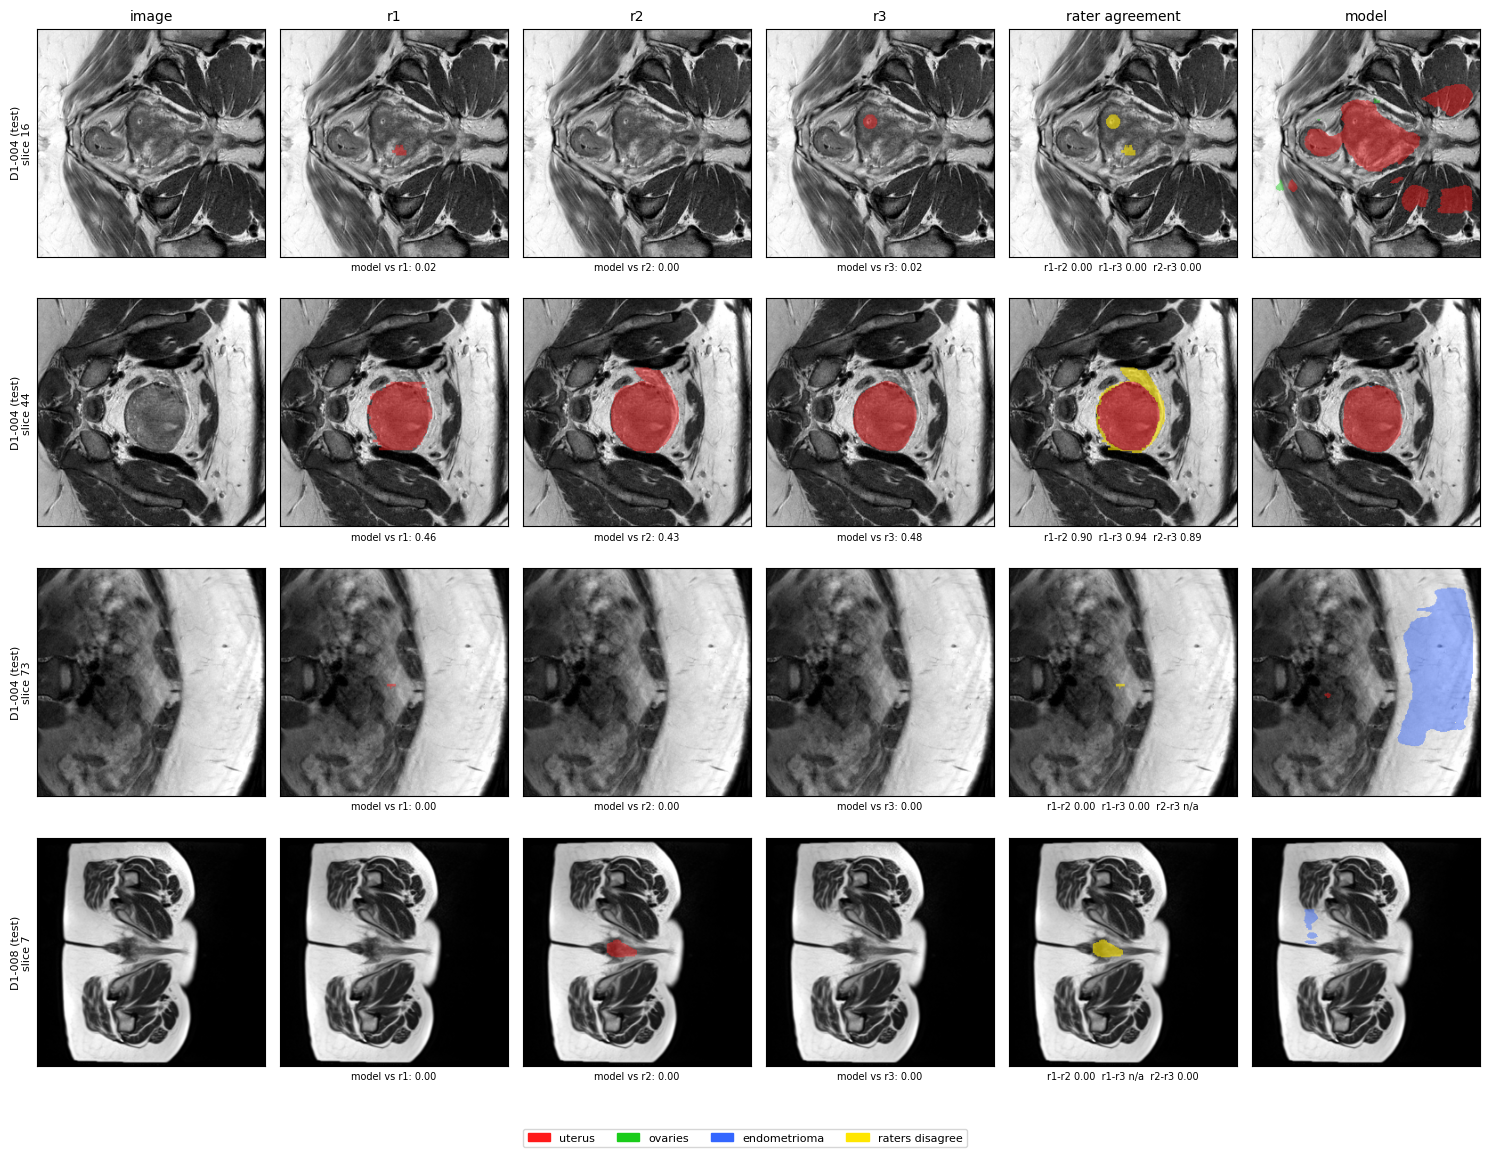

saved /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/rater_visual_checks/rater_visual_unet_A_only_seed42_1.png


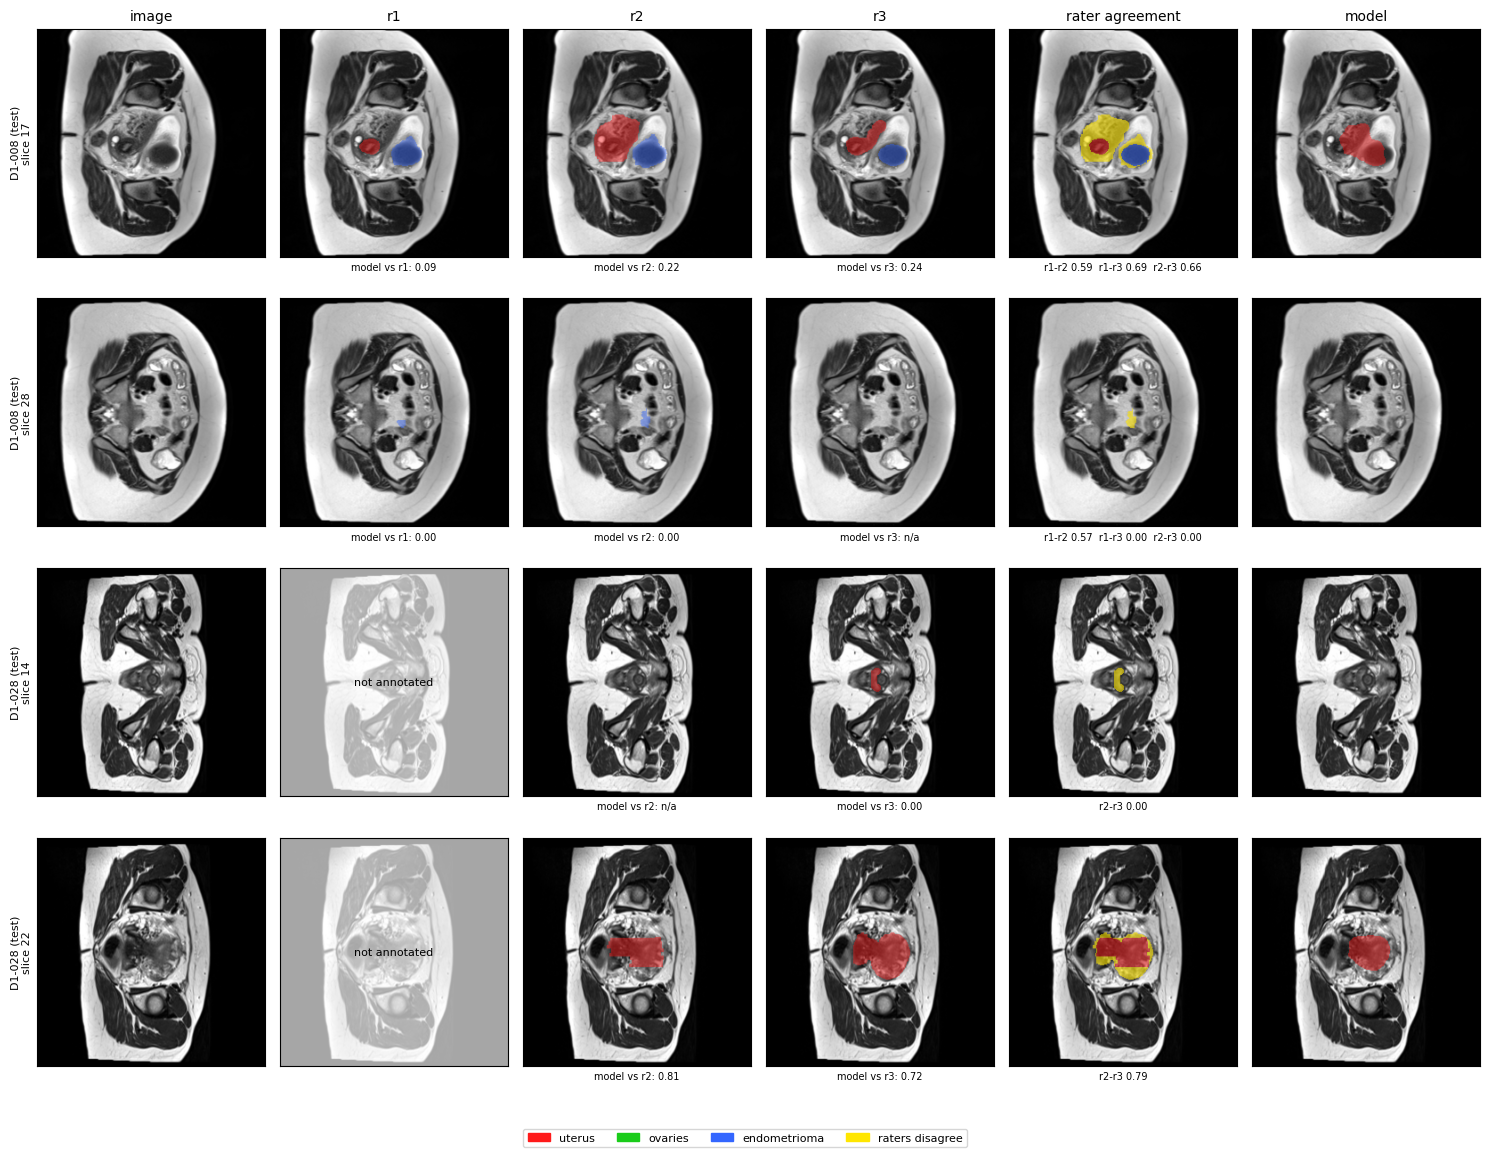

saved /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/rater_visual_checks/rater_visual_unet_A_only_seed42_2.png


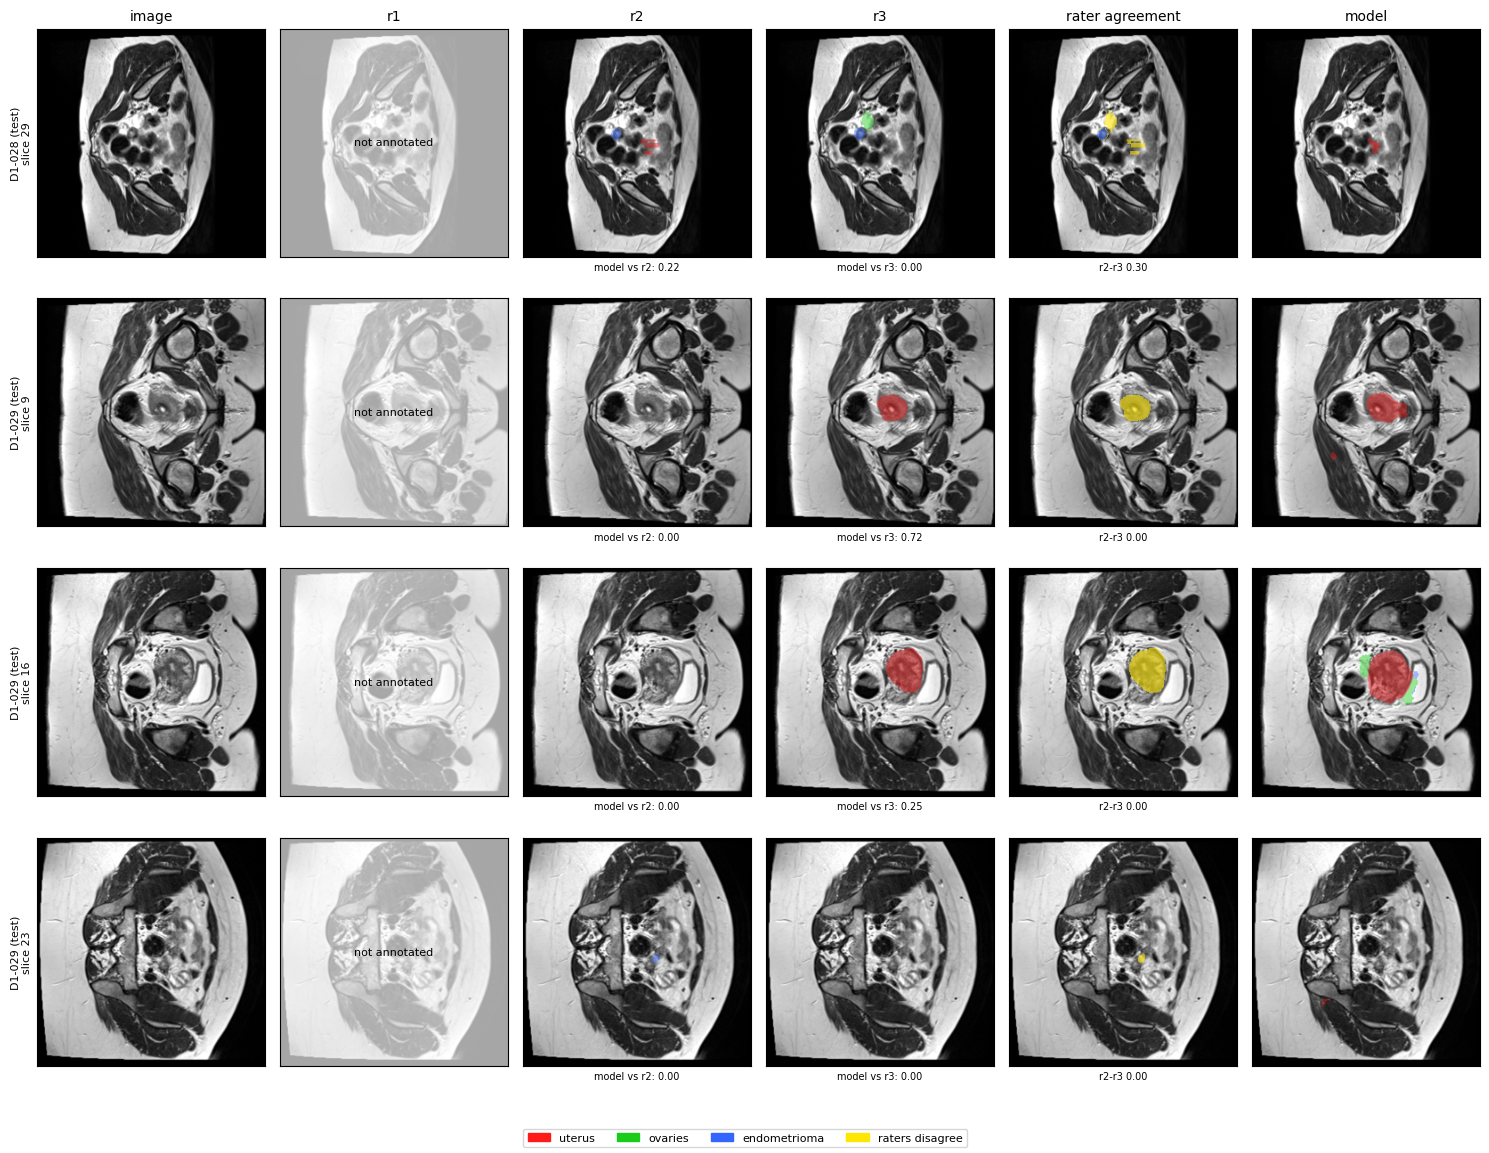

saved /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/rater_visual_checks/rater_visual_unet_A_only_seed42_3.png


In [ ]:
"""
Visual check: raters (r1 / r2 / r3) vs each other, and raters vs the model.
"""
import os
import re
import glob
import itertools
import numpy as np
import pandas as pd
import nibabel as nib
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from skimage.transform import resize

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
FOLDER_NAME = "new results"
CKPT_NAME = "unet_A_only_seed42.pt"   # raters are site D1, so use a model trained on A or pooled
SPLITS_NAME = "splits-2.csv"          # optional, only used to label patients train/val/test
CHECK_SEED = 42

CASE_IDS = None            # e.g. ["D1-004", "D1-020"], or None to choose automatically
SPLIT_FILTER = "test"      # automatic choice only from this split ("test", "val", "train" or None)
MIN_RATERS = 2             # automatic choice: patients annotated by at least this many raters
N_PATIENTS = 4
SLICES_PER_PATIENT = 3
ROWS_PER_FIGURE = 4
PLOT_SEED = 0
# -------------------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")


def find_folder(root, name, max_depth=3):
    root = root.rstrip("/")
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
            continue
        for d in dirnames:
            if d.lower() == name.lower():
                return os.path.join(dirpath, d)
    return None


PROJECT_DIR = os.path.join(DRIVE_ROOT, FOLDER_NAME)
if not os.path.isdir(PROJECT_DIR):
    PROJECT_DIR = find_folder(DRIVE_ROOT, FOLDER_NAME)
if PROJECT_DIR is None:
    raise FileNotFoundError(f"No folder named '{FOLDER_NAME}' found under {DRIVE_ROOT}.")
CKPT_PATH = os.path.join(PROJECT_DIR, CKPT_NAME)
if not os.path.isfile(CKPT_PATH):
    raise FileNotFoundError(f"{CKPT_PATH} not found. Files in that folder: {sorted(os.listdir(PROJECT_DIR))}")
SPLITS_PATH = os.path.join(PROJECT_DIR, SPLITS_NAME)
print("project folder:", PROJECT_DIR)
print("checkpoint    :", CKPT_PATH)

CLASS_IDS = list(range(1, NUM_CLASSES))
CLASS_COLORS = {1: (1.0, 0.1, 0.1), 2: (0.1, 0.8, 0.1), 3: (0.2, 0.4, 1.0)}   # uterus / ovaries / endometrioma
_RATER_RE = re.compile(r"_(?P<st>[a-z]+)_(?P<rater>r\d+)\.nii\.gz$")


# ------------------------------------------------------------ rater files
def case_rater_files(case):
    pdir = os.path.join(case["site_dir"], case["case_id"])
    out = {}
    for st in STRUCTURES_OF_INTEREST:
        for p in glob.glob(os.path.join(pdir, f"{case['case_id']}_{st}_r*.nii.gz")):
            m = _RATER_RE.search(os.path.basename(p))
            if m and m.group("st") == st:
                out.setdefault(m.group("rater"), {})[st] = p
    return out


def rater_label_paths(rater_files, rater):
    return {st: rater_files.get(rater, {}).get(st) for st in STRUCTURES_OF_INTEREST}


# ---------------------------------------------------------- slice helpers
def volumetric_dice(a, b):
    denom = a.sum() + b.sum()
    return np.nan if denom == 0 else 2.0 * np.logical_and(a, b).sum() / denom


def slice_dice(a, b):
    """Foreground Dice of two label slices: mean over organs present in either."""
    vals = [volumetric_dice(a == c, b == c) for c in CLASS_IDS]
    return np.nan if np.all(np.isnan(vals)) else float(np.nanmean(vals))


def prep_image_slice(img_vol, i):
    s = normalize_intensity(np.take(img_vol, i, axis=SLICE_AXIS))
    return resize(s, (IMAGE_SIZE, IMAGE_SIZE), order=1, preserve_range=True,
                  anti_aliasing=True).astype(np.float32)


def prep_mask_slice(mask_vol, i):
    return resize(np.take(mask_vol, i, axis=SLICE_AXIS), (IMAGE_SIZE, IMAGE_SIZE),
                  order=0, preserve_range=True, anti_aliasing=False).astype(np.int8)


def labelled_slices(native_masks):
    keep = None
    for m in native_masks.values():
        counts = (np.moveaxis(m, SLICE_AXIS, 0).reshape(m.shape[SLICE_AXIS], -1) > 0).sum(1)
        k = counts >= MIN_FOREGROUND_PIXELS
        keep = k if keep is None else (keep | k)
    return np.where(keep)[0]


def overlay(img, mask, alpha=0.45):
    rgb = np.stack([img] * 3, axis=-1).astype(np.float32)
    for c, col in CLASS_COLORS.items():
        m = mask == c
        if m.any():
            rgb[m] = (1 - alpha) * rgb[m] + alpha * np.array(col)
    return np.clip(rgb, 0, 1)


def agreement_overlay(img, masks, alpha=0.5):
    """Colour where all annotating raters agree on the class; yellow where they differ."""
    stack = np.stack(masks)                              # [k, H, W]
    same = (stack == stack[0]).all(axis=0)
    agree_fg = same & (stack[0] > 0)
    disagree = ~same
    rgb = overlay(img, np.where(agree_fg, stack[0], 0), alpha)
    rgb[disagree] = (1 - 0.6) * rgb[disagree] + 0.6 * np.array((1.0, 0.9, 0.0))
    return np.clip(rgb, 0, 1)


def fmt(x):
    return "n/a" if x is None or np.isnan(x) else f"{x:.2f}"


# ------------------------------------------------------------ model glue
def load_checkpoint_model(path, device):
    model = SmallUNet(1, NUM_CLASSES, BASE_CHANNELS).to(device)
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state"] if "model_state" in ckpt else ckpt)
    model.eval()
    return model


@torch.no_grad()
def predict_slices(model, imgs, device):
    x = torch.from_numpy(np.stack(imgs)).float().unsqueeze(1).to(device)
    return torch.argmax(model(x), dim=1).cpu().numpy().astype(np.int8)


# --------------------------------------------------------------- selection
def load_split_lookup():
    if not os.path.isfile(SPLITS_PATH):
        print(f"[info] {SPLITS_NAME} not found: patients will not be labelled train/val/test")
        return {}
    df = pd.read_csv(SPLITS_PATH)
    if "seed" in df.columns:
        df = df[df["seed"] == CHECK_SEED]
    return dict(zip(df["case_id"], df["split"]))


def _load_site(site_dir, site_name):
    out = {}
    for c in discover_cases(site_dir):
        c = dict(c); c["site"] = site_name
        out[c["case_id"]] = c
    return out


def choose_cases(split_of):
    pool = _load_site(SITE_A_DIR, SITE_A_NAME)           # raters are annotated in site A (D1)
    if CASE_IDS:
        if any(i not in pool for i in CASE_IDS):         # only touch site B if asked for it
            pool.update(_load_site(SITE_B_DIR, SITE_B_NAME))
        missing = [i for i in CASE_IDS if i not in pool]
        if missing:
            raise ValueError(f"Not usable (no T2 image or no labels): {missing}")
        return [pool[i] for i in CASE_IDS]
    if SPLIT_FILTER and not split_of:
        raise RuntimeError(f"SPLIT_FILTER='{SPLIT_FILTER}' needs {SPLITS_NAME}; set SPLIT_FILTER=None "
                           f"or CASE_IDS explicitly.")
    cand = []
    for c in pool.values():
        if SPLIT_FILTER and split_of.get(c["case_id"]) != SPLIT_FILTER:
            continue
        n = len(case_rater_files(c))
        if n >= MIN_RATERS:
            cand.append((n, c))
    if not cand:
        raise RuntimeError("No patient matches (annotated by enough raters, in that split).")
    rng = np.random.RandomState(PLOT_SEED)
    rng.shuffle(cand)
    cand.sort(key=lambda t: -t[0])                       # prefer patients with the most raters
    return [c for _, c in cand[:N_PATIENTS]]


# --------------------------------------------------------------------- run
def run_rater_visual_check():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    split_of = load_split_lookup()
    cases = choose_cases(split_of)
    model = load_checkpoint_model(CKPT_PATH, device)

    patient_data, all_raters = [], set()
    for c in cases:
        files = case_rater_files(c)
        if not files:
            raise RuntimeError(f"{c['case_id']}: no rater label files found")
        all_raters |= set(files)
        image_nii = nib.as_closest_canonical(nib.load(c["image_path"]))
        img_vol = image_nii.get_fdata().astype(np.float32)
        native = {r: load_combined_mask(image_nii, rater_label_paths(files, r)) for r in files}
        idx = labelled_slices(native)
        if len(idx) == 0:
            print(f"[warn] {c['case_id']}: no labelled slices, skipped"); continue
        pick = np.unique(np.round(np.linspace(0, len(idx) - 1, min(SLICES_PER_PATIENT, len(idx)))).astype(int))
        pick = idx[pick]
        imgs = [prep_image_slice(img_vol, i) for i in pick]
        preds = predict_slices(model, imgs, device)
        for k, i in enumerate(pick):
            patient_data.append({
                "case_id": c["case_id"], "split": split_of.get(c["case_id"], "?"), "slice": int(i),
                "img": imgs[k], "pred": preds[k],
                "raters": {r: prep_mask_slice(native[r], i) for r in native}})
    raters = sorted(all_raters)
    ncols = 1 + len(raters) + 2
    out_dir = os.path.join(PROJECT_DIR, "rater_visual_checks")
    os.makedirs(out_dir, exist_ok=True)
    tag = os.path.splitext(CKPT_NAME)[0]

    legend = [Patch(color=CLASS_COLORS[c], label=LABEL_MAP[c]) for c in CLASS_COLORS]
    legend.append(Patch(color=(1.0, 0.9, 0.0), label="raters disagree"))
    n_figs = int(np.ceil(len(patient_data) / ROWS_PER_FIGURE))
    for f in range(n_figs):
        chunk = patient_data[f * ROWS_PER_FIGURE:(f + 1) * ROWS_PER_FIGURE]
        fig, axes = plt.subplots(len(chunk), ncols, figsize=(2.5 * ncols, 2.9 * len(chunk)), squeeze=False)
        for row, d in enumerate(chunk):
            img, pred, rm = d["img"], d["pred"], d["raters"]
            ann = [r for r in raters if r in rm]
            axes[row, 0].imshow(img, cmap="gray")
            axes[row, 0].set_ylabel(f"{d['case_id']} ({d['split']})\nslice {d['slice']}", fontsize=8)
            for j, r in enumerate(raters):
                ax = axes[row, 1 + j]
                if r in rm:
                    ax.imshow(overlay(img, rm[r]))
                else:
                    ax.imshow(img, cmap="gray", alpha=0.35)
                    ax.text(0.5, 0.5, "not annotated", ha="center", va="center",
                            transform=ax.transAxes, fontsize=8)
                if r in rm:
                    ax.set_xlabel(f"model vs {r}: {fmt(slice_dice(pred, rm[r]))}", fontsize=7)
            ax_ag = axes[row, 1 + len(raters)]
            if len(ann) >= 2:
                ax_ag.imshow(agreement_overlay(img, [rm[r] for r in ann]))
                pairs = [f"{a}-{b} {fmt(slice_dice(rm[a], rm[b]))}" for a, b in itertools.combinations(ann, 2)]
                ax_ag.set_xlabel("  ".join(pairs), fontsize=7)
            else:
                ax_ag.imshow(img, cmap="gray", alpha=0.35)
                ax_ag.text(0.5, 0.5, "only one rater", ha="center", va="center",
                           transform=ax_ag.transAxes, fontsize=8)
            axes[row, -1].imshow(overlay(img, pred))
            for ax in axes[row]:
                ax.set_xticks([]); ax.set_yticks([])
        titles = ["image"] + raters + ["rater agreement", "model"]
        for ax, t in zip(axes[0], titles):
            ax.set_title(t, fontsize=10)
        fig.legend(handles=legend, loc="lower center", ncol=4, fontsize=8)
        fig.tight_layout(rect=(0, 0.04, 1, 1))
        out = os.path.join(out_dir, f"rater_visual_{tag}_{f + 1}.png")
        fig.savefig(out, dpi=130)
        plt.show()
        print("saved", out)


run_rater_visual_check()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none of ['D1-014_T2.nii.gz'] found. Files actually present: ['D1-014_T1FS.nii.gz', 'D1-014_em_r3.nii.gz', 'D1-014_ut_r3.nii.gz']
[warn] D1-014: skippi

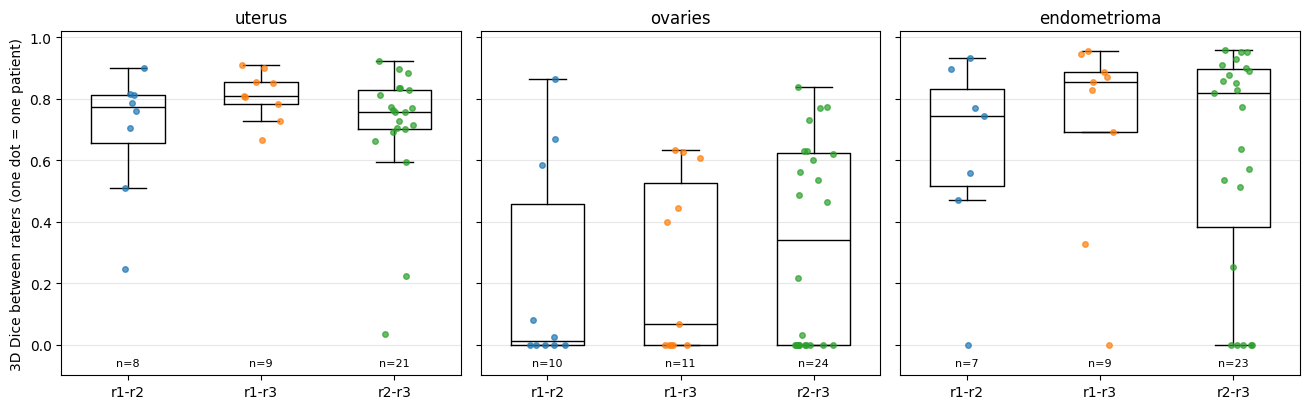

saved /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/rater_agreement_pairwise/fig_pairwise_dice.png

all outputs saved to: /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/rater_agreement_pairwise


In [ ]:
"""
Inter-rater agreement, PAIRWISE and availability-aware (replaces the all-three-raters Part 1).

For every pair of raters it uses ALL patients that both raters annotated (not just the few that
all three did). Missing files are handled like this:
  * UTERUS: every patient has one, so a missing uterus file means "not annotated" -> that rater is
    EXCLUDED for that patient
  * OVARIES / ENDOMETRIOMA: a missing file can mean "none found", so for patients a rater annotated
    it counts as an empty mask
    If both are empty the patient has no value for that organ.
"""
import os
import re
import glob
import itertools
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare, wilcoxon

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
FOLDER_NAME = "new results"          # outputs go to <folder>/rater_agreement_pairwise
MIN_PATIENTS_FOR_TESTS = 5
# -------------------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")


def find_folder(root, name, max_depth=3):
    root = root.rstrip("/")
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
            continue
        for d in dirnames:
            if d.lower() == name.lower():
                return os.path.join(dirpath, d)
    return None


PROJECT_DIR = os.path.join(DRIVE_ROOT, FOLDER_NAME)
if not os.path.isdir(PROJECT_DIR):
    PROJECT_DIR = find_folder(DRIVE_ROOT, FOLDER_NAME)
if PROJECT_DIR is None:
    raise FileNotFoundError(f"No folder named '{FOLDER_NAME}' found under {DRIVE_ROOT}.")
OUT_DIR = os.path.join(PROJECT_DIR, "rater_agreement_pairwise")
os.makedirs(OUT_DIR, exist_ok=True)

CLASS_IDS = list(range(1, NUM_CLASSES))
ABBR = {LABEL_MAP[cid]: st for st, cid in STRUCTURES_OF_INTEREST.items()}   # 'uterus' -> 'ut'
_RATER_RE = re.compile(r"_(?P<st>[a-z]+)_(?P<rater>r\d+)\.nii\.gz$")


def case_rater_files(case):
    pdir = os.path.join(case["site_dir"], case["case_id"])
    out = {}
    for st in STRUCTURES_OF_INTEREST:
        for p in glob.glob(os.path.join(pdir, f"{case['case_id']}_{st}_r*.nii.gz")):
            m = _RATER_RE.search(os.path.basename(p))
            if m and m.group("st") == st:
                out.setdefault(m.group("rater"), {})[st] = p
    return out


def rater_label_paths(rater_files, rater):
    return {st: rater_files.get(rater, {}).get(st) for st in STRUCTURES_OF_INTEREST}


def volumetric_dice(a, b):
    denom = a.sum() + b.sum()
    return np.nan if denom == 0 else 2.0 * np.logical_and(a, b).sum() / denom


def icc_2_1(X):
    n, k = X.shape
    gm = X.mean()
    ss_r = k * ((X.mean(1) - gm) ** 2).sum()
    ss_c = n * ((X.mean(0) - gm) ** 2).sum()
    ss_e = ((X - gm) ** 2).sum() - ss_r - ss_c
    msr, msc, mse = ss_r / (n - 1), ss_c / (k - 1), ss_e / ((n - 1) * (k - 1))
    d = msr + (k - 1) * mse + k * (msc - mse) / n
    return (msr - mse) / d if d > 0 else np.nan


def holm(p):
    p = np.asarray(p, float)
    out, prev = np.full(len(p), np.nan), 0.0
    idx = np.where(~np.isnan(p))[0]
    for rank, i in enumerate(idx[np.argsort(p[idx])]):
        prev = max(prev, (len(idx) - rank) * p[i])
        out[i] = min(1.0, prev)
    return out


def participates(files, rater, organ):
    """Does this rater provide a usable value for this organ in this patient?"""
    if rater not in files:
        return False                                   # rater did not annotate the patient at all
    if organ == "uterus":
        return "ut" in files[rater]                    # uterus: missing file = not annotated
    return True                                        # lesions/ovaries: missing file = none found


def collect(cases):
    files_all = {c["case_id"]: case_rater_files(c) for c in cases}
    raters = sorted({r for f in files_all.values() for r in f})
    pair_rows, vol_rows = [], []
    for c in cases:
        cid, files = c["case_id"], files_all[c["case_id"]]
        if len(files) < 2:
            continue
        image_nii = nib.as_closest_canonical(nib.load(c["image_path"]))
        vox_ml = float(np.prod(np.sqrt((image_nii.affine[:3, :3] ** 2).sum(0)))) / 1000.0
        masks = {r: load_combined_mask(image_nii, rater_label_paths(files, r)) for r in files}
        for cls in CLASS_IDS:
            organ = LABEL_MAP[cls]
            have = [r for r in sorted(files) if participates(files, r, organ)]
            for r in have:
                vol_rows.append({"case_id": cid, "organ": organ, "rater": r,
                                 "volume_ml": float((masks[r] == cls).sum()) * vox_ml})
            for ra, rb in itertools.combinations(have, 2):
                pair_rows.append({"case_id": cid, "organ": organ, "pair": f"{ra}-{rb}",
                                  "dice": volumetric_dice(masks[ra] == cls, masks[rb] == cls)})
    return raters, pd.DataFrame(pair_rows), pd.DataFrame(vol_rows)


def run_pairwise_agreement():
    cases = discover_cases(SITE_A_DIR)
    raters, pair_df, vol_df = collect(cases)
    pair_df.to_csv(os.path.join(OUT_DIR, "pairwise_dice.csv"), index=False)
    vol_df.to_csv(os.path.join(OUT_DIR, "volumes.csv"), index=False)
    organs = [LABEL_MAP[c] for c in CLASS_IDS]
    pairs = [f"{a}-{b}" for a, b in itertools.combinations(raters, 2)]

    print(f"raters: {raters}")
    print("\n=== Pairwise 3D Dice (mean / std / median / n patients with a value) ===")
    t = pair_df.groupby(["organ", "pair"])["dice"].agg(["mean", "std", "median", "count"]).round(3)
    print(t)
    t.to_csv(os.path.join(OUT_DIR, "table_pairwise_dice.csv"))

    print("\n=== Mean volume (mL) per rater, over patients where that rater has the organ ===")
    print(vol_df.pivot_table(index="organ", columns="rater", values="volume_ml",
                             aggfunc=["mean", "count"]).round(1))

    print("\n=== Do two raters label systematically different volumes? (paired, patients both annotated) ===")
    rows = []
    for organ in organs:
        w = vol_df[vol_df.organ == organ].pivot(index="case_id", columns="rater", values="volume_ml")
        ps, labs = [], []
        for ra, rb in itertools.combinations(raters, 2):
            both = w[[ra, rb]].dropna()
            both = both[(both > 0).any(axis=1)]                    # drop patients where both are empty
            if len(both) < MIN_PATIENTS_FOR_TESTS:
                rows.append({"organ": organ, "pair": f"{ra}-{rb}", "n": len(both)}); continue
            d = both[ra] - both[rb]
            p = wilcoxon(d).pvalue if (d != 0).any() else np.nan
            rows.append({"organ": organ, "pair": f"{ra}-{rb}", "n": len(both),
                         "mean_diff_ml": d.mean(), "p": p, "icc_2_1": icc_2_1(both.values)})
        part = [r for r in rows if r["organ"] == organ and "p" in r]
        for r, a in zip(part, holm([r["p"] for r in part])):
            r["p_holm"] = a
        allthree = w.dropna()
        allthree = allthree[(allthree > 0).any(axis=1)]
        if (len(raters) >= 3 and len(allthree) >= MIN_PATIENTS_FOR_TESTS
                and not np.allclose(allthree.values, allthree.values[:, [0]])):
            fp = friedmanchisquare(*[allthree[r].values for r in raters]).pvalue
            print(f"  {organ}: Friedman across all raters p={fp:.3f} (n={len(allthree)} patients all three have it)")
    tv = pd.DataFrame(rows)
    print(tv.round(3).to_string(index=False))
    tv.to_csv(os.path.join(OUT_DIR, "table_volume_tests.csv"), index=False)

    # figure: pairwise Dice per patient
    fig, axes = plt.subplots(1, len(organs), figsize=(4.4 * len(organs), 4.2), sharey=True)
    rng = np.random.RandomState(0)
    for ax, organ in zip(np.atleast_1d(axes), organs):
        for k, pr in enumerate(pairs):
            x = pair_df[(pair_df.organ == organ) & (pair_df.pair == pr)]["dice"].dropna().values
            if len(x):
                ax.boxplot(x, positions=[k], widths=.55, showfliers=False, medianprops=dict(color="k"))
                ax.scatter(k + rng.uniform(-.15, .15, len(x)), x, s=16, alpha=.7, zorder=3)
            ax.text(k, -0.07, f"n={len(x)}", ha="center", fontsize=8)
        ax.set_xticks(range(len(pairs))); ax.set_xticklabels(pairs); ax.set_ylim(-0.1, 1.02)
        ax.set_title(organ); ax.grid(axis="y", alpha=.3)
    np.atleast_1d(axes)[0].set_ylabel("3D Dice between raters (one dot = one patient)")
    fig.tight_layout()
    out = os.path.join(OUT_DIR, "fig_pairwise_dice.png")
    fig.savefig(out, dpi=140); plt.show(); print("saved", out)
    print("\nall outputs saved to:", OUT_DIR)
    return pair_df, vol_df


df_pair, df_vol = run_pairwise_agreement()

In [ ]:
"""
does the rater whose labels
are used for training/evaluation change the model?   Site A / D1 only.

UTERUS RULE: every patient has a uterus, so a missing uterus file means "not annotated".
Such patients are excluded from training for that rater, and the uterus is not scored against
a rater who did not annotate it (it is never counted as an empty mask).
"""
import os
import re
import glob
import json
import hashlib
import itertools
import numpy as np
import pandas as pd
import nibabel as nib
import torch
from torch.utils.data import DataLoader
from skimage.transform import resize
from scipy.stats import friedmanchisquare, wilcoxon

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
FOLDER_NAME = "endometriosis"       # project folder; outputs go to <folder>/rater_part2
RATER_SEEDS = [42]
SPLIT_VAL_FRACTION = 0.15
SPLIT_TEST_FRACTION = 0.20
USE_SAVED_SPLITS = False

SPLITS_NAME = "splits.csv"
MIN_RATER_PATIENTS = 15             # a rater needs this many annotated patients to train a model
TRAIN_RATERS = None
MATCH_TRAIN_PATIENTS = True
MIN_TRAIN_PATIENTS, MIN_VAL_PATIENTS = 8, 2
EVAL_SLICE_MODE = "union"
# -------------------------------------------------------------------------

if not os.path.isdir(DRIVE_ROOT):
    from google.colab import drive
    drive.mount("/content/drive")


def find_folder(root, name, max_depth=3):
    root = root.rstrip("/")
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
            continue
        for d in dirnames:
            if d.lower() == name.lower():
                return os.path.join(dirpath, d)
    return None


PROJECT_DIR = find_folder(DRIVE_ROOT, FOLDER_NAME)
if PROJECT_DIR is None:
    raise FileNotFoundError(f"No folder '{FOLDER_NAME}' under {DRIVE_ROOT}.")
SPLITS_PATH = None
if USE_SAVED_SPLITS:
    _hits = glob.glob(os.path.join(PROJECT_DIR, "**", SPLITS_NAME), recursive=True)
    if not _hits:
        raise FileNotFoundError(f"{SPLITS_NAME} not found under {PROJECT_DIR}")
    SPLITS_PATH = _hits[0]
RATER_OUT_DIR = os.path.join(PROJECT_DIR, "rater_part2")   # everything is saved here
os.makedirs(RATER_OUT_DIR, exist_ok=True)
print("outputs to :", RATER_OUT_DIR)

_RATER_RE = re.compile(r"_(?P<st>[a-z]+)_(?P<rater>r\d+)\.nii\.gz$")
CLASS_IDS = list(range(1, NUM_CLASSES))


# ------------------------------------------------------------ rater files
def case_rater_files(case):
    pdir = os.path.join(case["site_dir"], case["case_id"])
    out = {}
    for st in STRUCTURES_OF_INTEREST:
        for p in glob.glob(os.path.join(pdir, f"{case['case_id']}_{st}_r*.nii.gz")):
            m = _RATER_RE.search(os.path.basename(p))
            if m and m.group("st") == st:
                out.setdefault(m.group("rater"), {})[st] = p
    return out


def rater_label_paths(rater_files, rater):
    return {st: rater_files.get(rater, {}).get(st) for st in STRUCTURES_OF_INTEREST}


def with_rater(case, files, rater):
    c = dict(case)
    c["label_paths"] = rater_label_paths(files[case["case_id"]], rater)
    return c


def audit_raters(cases):
    files = {c["case_id"]: case_rater_files(c) for c in cases}
    raters = sorted({r for f in files.values() for r in f})
    if len(raters) < 2:
        raise RuntimeError(f"Found raters {raters}; need at least 2.")
    rows = []
    for r in raters:
        row = {"rater": r, "patients_annotated": sum(r in f for f in files.values())}
        for st in STRUCTURES_OF_INTEREST:
            row[f"{st}_files"] = sum(st in f.get(r, {}) for f in files.values())
        rows.append(row)
    print("=== Annotation availability (site A, T2 patients) ===")
    print(pd.DataFrame(rows).to_string(index=False))
    ov = pd.DataFrame({rb: {ra: sum(ra in f and rb in f for f in files.values())
                            for ra in raters} for rb in raters})
    print("\n=== Patients annotated by BOTH raters (overlap matrix) ===")
    print(ov.to_string())
    return files, raters


def choose_train_raters(files, raters):
    counts = {r: sum("ut" in f.get(r, {}) for f in files.values()) for r in raters}   # uterus files
    if TRAIN_RATERS:
        chosen = list(TRAIN_RATERS)
    else:
        chosen = [r for r in raters if counts[r] >= MIN_RATER_PATIENTS]
        dropped = [r for r in raters if r not in chosen]
        if dropped:
            print(f"\n[info] not training on {dropped}: fewer than {MIN_RATER_PATIENTS} patients with "
                  f"a uterus label ({ {r: counts[r] for r in dropped} }). They are still used as "
                  f"EVALUATION references where they annotated test patients.")
    if len(chosen) < 2:
        raise RuntimeError(f"Need >= 2 raters to train on, got {chosen}. Lower MIN_RATER_PATIENTS "
                           f"or set TRAIN_RATERS explicitly.")
    print(f"[info] training raters: {chosen}")
    return chosen


def has_uterus(files, cid, rater):
    return "ut" in files[cid].get(rater, {})


def annotated_by(cases, files, raters):
    """Patients where every listed rater contoured the uterus."""
    return [c for c in cases if all(has_uterus(files, c["case_id"], r) for r in raters)]


def score_available(pred, gt, keep, files, cid, raters_involved):
    """Per-class Dice, but the uterus is NaN if any involved rater did not annotate it."""
    sc = list(score_volume(pred, gt, keep))
    if not all(has_uterus(files, cid, r) for r in raters_involved):
        sc[CLASS_IDS.index(STRUCTURES_OF_INTEREST["ut"])] = np.nan
    return sc


def split_cases_three_way(cases, val_fraction, test_fraction, seed):
    rng = np.random.RandomState(seed)
    idx = np.arange(len(cases))
    rng.shuffle(idx)
    n = len(idx)
    n_test = max(1, int(round(n * test_fraction)))
    n_val = max(1, int(round(n * val_fraction)))
    if n - n_test - n_val < 1:
        raise ValueError(f"Only {n} cases.")
    pick = lambda ids: [cases[i] for i in sorted(ids)]
    return pick(idx[n_test + n_val:]), pick(idx[n_test:n_test + n_val]), pick(idx[:n_test])


def cases_from_splits(splits_path, seed, cases_a):
    df = pd.read_csv(splits_path)
    if "seed" in df.columns:
        if seed not in set(df["seed"]):
            raise ValueError(f"seed {seed} not in splits.csv (has {sorted(set(df['seed']))})")
        df = df[df["seed"] == seed]
    df = df[df["site"] == "A"]
    by_id = {c["case_id"]: c for c in cases_a}
    out = []
    for split in ["train", "val", "test"]:
        wanted = set(df.loc[df["split"] == split, "case_id"])
        missing = wanted - set(by_id)
        if missing:
            print(f"[warn] {len(missing)} {split} case_ids in splits.csv have no T2 image "
                  f"(e.g. {sorted(missing)[:3]}): this splits.csv is NOT from the T2-only setup.")
        out.append([by_id[c] for c in sorted(wanted & set(by_id))])
    return out


def get_site_a_split(cases_a, seed):
    if USE_SAVED_SPLITS:
        return cases_from_splits(SPLITS_PATH, seed, cases_a)
    tr, va, te = split_cases_three_way(cases_a, SPLIT_VAL_FRACTION, SPLIT_TEST_FRACTION, seed)
    rows = [{"seed": seed, "site": "A", "split": n, "case_id": c["case_id"]}
            for n, lst in [("train", tr), ("val", va), ("test", te)] for c in lst]
    pd.DataFrame(rows).to_csv(os.path.join(RATER_OUT_DIR, f"splits_siteA_T2_seed{seed}.csv"), index=False)
    return tr, va, te


def assert_no_overlap(A_tr, A_va, A_te):
    sets = {"train": A_tr, "val": A_va, "test": A_te}
    for (k1, v1), (k2, v2) in itertools.combinations(sets.items(), 2):
        assert not ({c["case_id"] for c in v1} & {c["case_id"] for c in v2}), f"LEAK {k1}/{k2}"
        assert not ({c["image_path"] for c in v1} & {c["image_path"] for c in v2}), f"LEAK {k1}/{k2}"
    print(f"[leak-check] train={len(A_tr)} val={len(A_va)} test={len(A_te)} patients: disjoint")


# -------------------------------------------------------------- metrics
def volumetric_dice(a, b):
    denom = a.sum() + b.sum()
    return np.nan if denom == 0 else 2.0 * np.logical_and(a, b).sum() / denom


def to_model_space(mask_vol):
    n = mask_vol.shape[SLICE_AXIS]
    return np.stack([
        resize(np.take(mask_vol, i, axis=SLICE_AXIS), (IMAGE_SIZE, IMAGE_SIZE),
               order=0, preserve_range=True, anti_aliasing=False).astype(np.int8)
        for i in range(n)])


def union_slice_keep(native_masks):
    keep = None
    for m in native_masks.values():
        counts = (np.moveaxis(m, SLICE_AXIS, 0).reshape(m.shape[SLICE_AXIS], -1) > 0).sum(1)
        k = counts >= MIN_FOREGROUND_PIXELS
        keep = k if keep is None else (keep | k)
    return keep


def score_volume(pred, gt, keep=None):
    if keep is not None:
        pred, gt = pred[keep], gt[keep]
    return [volumetric_dice(pred == c, gt == c) for c in CLASS_IDS]


def _row(base, scores):
    row = dict(base)
    for cid, s in zip(CLASS_IDS, scores):
        row[f"dice_{LABEL_MAP[cid]}"] = s
    row["dice_foreground_mean"] = (np.nan if np.all(np.isnan(scores)) else np.nanmean(scores))
    return row


def _bci(x, n_boot=5000, seed=0):
    rng = np.random.RandomState(seed)
    return np.percentile([rng.choice(x, len(x)).mean() for _ in range(n_boot)], [2.5, 97.5])


# ------------------------------------------------- training / prediction
def get_dev():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def _set_seed(seed):
    import random
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


@torch.no_grad()
def _val_dice(model, loader, device):
    model.eval()
    all_dice = []
    for images, masks, _ in loader:
        preds = torch.argmax(model(images.to(device)), dim=1).cpu()
        for p, m in zip(preds, masks):
            all_dice.append(dice_per_class(p, m, NUM_CLASSES))
    return np.nanmean(np.array(all_dice), axis=0)


def train_rater_model(train_ds, val_ds, ckpt_path, seed):
    """Train + checkpoint selection on validation only"""
    _set_seed(seed)
    device = get_dev()
    tl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    vl = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    model = SmallUNet(1, NUM_CLASSES, BASE_CHANNELS).to(device)
    criterion = DiceCELoss(NUM_CLASSES)
    opt = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=4)
    best, hist = -1.0, []
    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        run = 0.0
        for images, masks, _ in tl:
            images, masks = images.to(device), masks.to(device)
            opt.zero_grad()
            loss = criterion(model(images), masks)
            loss.backward()
            opt.step()
            run += loss.item() * images.size(0)
        v = float(np.nanmean(_val_dice(model, vl, device)[1:]))
        sched.step(v)
        hist.append({"epoch": epoch, "train_loss": run / len(train_ds), "val_dice_fg": v})
        print(f"  [epoch {epoch:03d}] train_loss={run / len(train_ds):.4f} val_fg_dice={v:.3f}")
        if v > best:
            best = v
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_dice_fg": v}, ckpt_path)
    pd.DataFrame(hist).to_csv(ckpt_path.replace(".pt", "_history.csv"), index=False)
    return best


def load_rater_model(path, device):
    model = SmallUNet(1, NUM_CLASSES, BASE_CHANNELS).to(device)
    ck = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(ck["model_state"] if "model_state" in ck else ck)
    model.eval()
    return model


@torch.no_grad()
def predict_case_volume(model, case, device, batch=16):
    img_vol = nib.as_closest_canonical(nib.load(case["image_path"])).get_fdata().astype(np.float32)
    n = img_vol.shape[SLICE_AXIS]
    sl = [resize(normalize_intensity(np.take(img_vol, i, axis=SLICE_AXIS)),
                 (IMAGE_SIZE, IMAGE_SIZE), order=1, preserve_range=True, anti_aliasing=True)
          for i in range(n)]
    x = torch.from_numpy(np.stack(sl)).float().unsqueeze(1)
    out = [torch.argmax(model(x[k:k + batch].to(device)), dim=1).cpu() for k in range(0, n, batch)]
    return torch.cat(out).numpy().astype(np.int8)


# ---------------------------------------------------------------- summary
def summarize_rater_model(df, df_rr, train_raters):
    fg = "dice_foreground_mean"
    dcols = [f"dice_{LABEL_MAP[c]}" for c in CLASS_IDS]
    print("\n=== Foreground Dice: model trained on (rows) vs evaluated against (columns) ===")
    print(df.pivot_table(index="train_rater", columns="eval_rater", values=fg, aggfunc="mean").round(3))
    print("\n--- number of test patients behind each cell ---")
    print(df.pivot_table(index="train_rater", columns="eval_rater", values="case_id",
                         aggfunc="nunique").fillna(0).astype(int))

    print("\n=== Per-class Dice: model vs own rater / vs other raters / rater vs rater ===")
    own_m = df[df.train_rater == df.eval_rater]
    oth_m = df[df.train_rater != df.eval_rater]
    print(pd.DataFrame({"model vs own rater": own_m[dcols].mean(),
                        "model vs other raters": oth_m[dcols].mean(),
                        "rater vs rater": df_rr[dcols].mean()}).round(3))

    print("\n=== Own-rater advantage (paired on patients annotated by both raters) ===")
    for r in train_raters:
        own = df[(df.train_rater == r) & (df.eval_rater == r)].set_index(["seed", "case_id"])[fg]
        oth = df[(df.train_rater == r) & (df.eval_rater != r)].groupby(["seed", "case_id"])[fg].mean()
        d = (own - oth).dropna().values
        if len(d) < 3:
            print(f"  model {r}: only {len(d)} test patients annotated by both - skipped"); continue
        lo, hi = _bci(d)
        p = wilcoxon(d).pvalue if (d != 0).any() and len(d) >= 5 else float("nan")
        print(f"  model {r}: mean {d.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  "
              f"Wilcoxon p={p:.3f}  (n={len(d)})")

    print("\n=== Does the TRAINING rater matter? (same patients, same evaluation rater) ===")
    for ev in sorted(df.eval_rater.unique()):
        w = (df[df.eval_rater == ev].pivot_table(index=["seed", "case_id"],
             columns="train_rater", values=fg).reindex(columns=train_raters).dropna())
        if len(w) < 5 or np.allclose(w.values, w.values[:, [0]]):
            print(f"  evaluated vs {ev}: only {len(w)} patients / identical - skipped"); continue
        if len(train_raters) >= 3:
            p, test = friedmanchisquare(*[w[t].values for t in train_raters]).pvalue, "Friedman"
        else:
            d = w[train_raters[0]] - w[train_raters[1]]
            p, test = (wilcoxon(d).pvalue if (d != 0).any() else float("nan")), "Wilcoxon"
        print(f"  evaluated vs {ev}: {test} p={p:.4f}  (means: "
              + ", ".join(f"{t}={w[t].mean():.3f}" for t in train_raters) + f", n={len(w)})")

    print("\n=== Ceiling check: mean foreground Dice ===")
    print(df_rr.groupby("pair")[fg].agg(["mean", "count"]).round(3).rename(
        columns={"mean": "rater vs rater", "count": "n patients"}))
    print(f"  model vs own rater:    {own_m[fg].mean():.3f}  (n={len(own_m)})")
    print(f"  model vs other raters: {oth_m[fg].mean():.3f}  (n={len(oth_m)})")


# ----------------------------------------------------------------- driver
def run_part2():
    device = get_dev()
    cases_a = discover_cases(SITE_A_DIR)
    for c in cases_a:
        c["site"] = SITE_A_NAME
    files, raters = audit_raters(cases_a)
    train_raters = choose_train_raters(files, raters)

    all_rows, rr_rows = [], []
    for seed in RATER_SEEDS:
        A_tr, A_va, A_te = get_site_a_split(cases_a, seed)
        assert_no_overlap(A_tr, A_va, A_te)
        print("\n=== patients with a uterus label, per rater and split ===")
        print(pd.DataFrame({n: {r: sum(has_uterus(files, c["case_id"], r) for c in lst) for r in raters}
                            for n, lst in [("train", A_tr), ("val", A_va), ("test", A_te)]}).T)

        # same training patients for every model -> only the labels differ
        shared = train_raters if MATCH_TRAIN_PATIENTS else None
        train_sets = {}
        for r in train_raters:
            req = shared if shared else [r]
            tr, va = annotated_by(A_tr, files, req), annotated_by(A_va, files, req)
            if len(tr) < MIN_TRAIN_PATIENTS or len(va) < MIN_VAL_PATIENTS:
                raise RuntimeError(
                    f"Rater {r}: only {len(tr)} train / {len(va)} val patients (need "
                    f"{MIN_TRAIN_PATIENTS}/{MIN_VAL_PATIENTS}). Set MATCH_TRAIN_PATIENTS=False, "
                    f"choose other TRAIN_RATERS, or lower the thresholds.")
            train_sets[r] = (tr, va)
        n_tr, n_va = len(train_sets[train_raters[0]][0]), len(train_sets[train_raters[0]][1])
        print(f"\n[train] each model: {n_tr} train / {n_va} val patients"
              + (" (identical patients for all models)" if shared else " (patients differ per rater!)"))

        # ground truth of every ANNOTATING rater for every test patient
        gt, keep, ann = {}, {}, {}
        for c in A_te:
            cid = c["case_id"]
            ann[cid] = [r for r in raters if r in files[cid]]
            image_nii = nib.as_closest_canonical(nib.load(c["image_path"]))
            native = {r: load_combined_mask(image_nii, rater_label_paths(files[cid], r)) for r in ann[cid]}
            gt[cid] = {r: to_model_space(m) for r, m in native.items()}
            keep[cid] = union_slice_keep(native) if EVAL_SLICE_MODE == "union" else None
        print(f"[test] {len(A_te)} patients; annotated by >=2 raters: "
              f"{sum(len(v) >= 2 for v in ann.values())}")

        for c in A_te:                                   # rater-vs-rater reference
            cid = c["case_id"]
            for ra, rb in itertools.combinations(ann[cid], 2):
                rr_rows.append(_row({"seed": seed, "case_id": cid, "pair": f"{ra} vs {rb}"},
                                    score_available(gt[cid][ra], gt[cid][rb], keep[cid], files, cid, [ra, rb])))

        for r in train_raters:
            tr, va = train_sets[r]
            sig = hashlib.md5(json.dumps([r, sorted(x["case_id"] for x in tr),
                                          sorted(x["case_id"] for x in va), EVAL_SLICE_MODE,
                                          NUM_EPOCHS, "uterus-rule-v2"]).encode()).hexdigest()[:8]
            tag = f"{r}_seed{seed}_{sig}"
            rows_path = os.path.join(RATER_OUT_DIR, f"rows_{tag}.csv")
            if os.path.exists(rows_path):
                print(f"\n[resume] {tag}: evaluation already saved, skipping")
                all_rows.append(pd.read_csv(rows_path)); continue

            ckpt = os.path.join(RATER_OUT_DIR, f"unet_rater_{tag}.pt")
            marker = os.path.join(RATER_OUT_DIR, f"done_{tag}.json")
            if os.path.exists(marker):
                print(f"\n[resume] {tag}: training already finished, skipping")
            else:
                print(f"\n{'=' * 60}\n seed={seed}  training on rater {r}\n{'=' * 60}")
                tr_ds = EndoMRISliceDataset([with_rater(c, files, r) for c in tr], SITE_A_NAME, augment=True)
                va_ds = EndoMRISliceDataset([with_rater(c, files, r) for c in va], SITE_A_NAME, augment=False)
                best = train_rater_model(tr_ds, va_ds, ckpt, seed)
                json.dump({"best_val_dice_fg": best}, open(marker, "w"))

            model = load_rater_model(ckpt, device)
            rows = []
            for c in A_te:
                cid = c["case_id"]
                pred = predict_case_volume(model, c, device)
                for rj in ann[cid]:
                    rows.append(_row({"seed": seed, "train_rater": r, "eval_rater": rj, "case_id": cid},
                                     score_available(pred, gt[cid][rj], keep[cid], files, cid, [rj])))
            part = pd.DataFrame(rows)
            part.to_csv(rows_path, index=False)
            all_rows.append(part)

    df = pd.concat(all_rows, ignore_index=True)
    df_rr = pd.DataFrame(rr_rows)
    df.to_csv(os.path.join(RATER_OUT_DIR, "rater_model_results.csv"), index=False)
    df_rr.to_csv(os.path.join(RATER_OUT_DIR, "rater_vs_rater_test_cases.csv"), index=False)
    if df.empty:
        raise RuntimeError("No test evaluations - no test patient was annotated. Check the audit above.")
    summarize_rater_model(df, df_rr, train_raters)
    return df, df_rr


df_rater_model, df_rater_rr = run_part2()

outputs to : /content/drive/MyDrive/Colab Notebooks/endometriosis/rater_part2
[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none of ['D1-014_T2.nii.gz'] found. Files actually present: ['D1-014_T1FS.nii.gz', 'D1-014_em_r3.nii.gz', 'D1-014_ut_r3.nii.gz']
[warn] D1-014: skipping patient (no usable sequence)
[warn] D1-019: none

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none of ['D1-014_T2.nii.gz'] found. Files actually present: ['D1-014_T1FS.nii.gz', 'D1-014_em_r3.nii.gz', 'D1-014_ut_r3.nii.gz']
[warn] D1-014: skippi

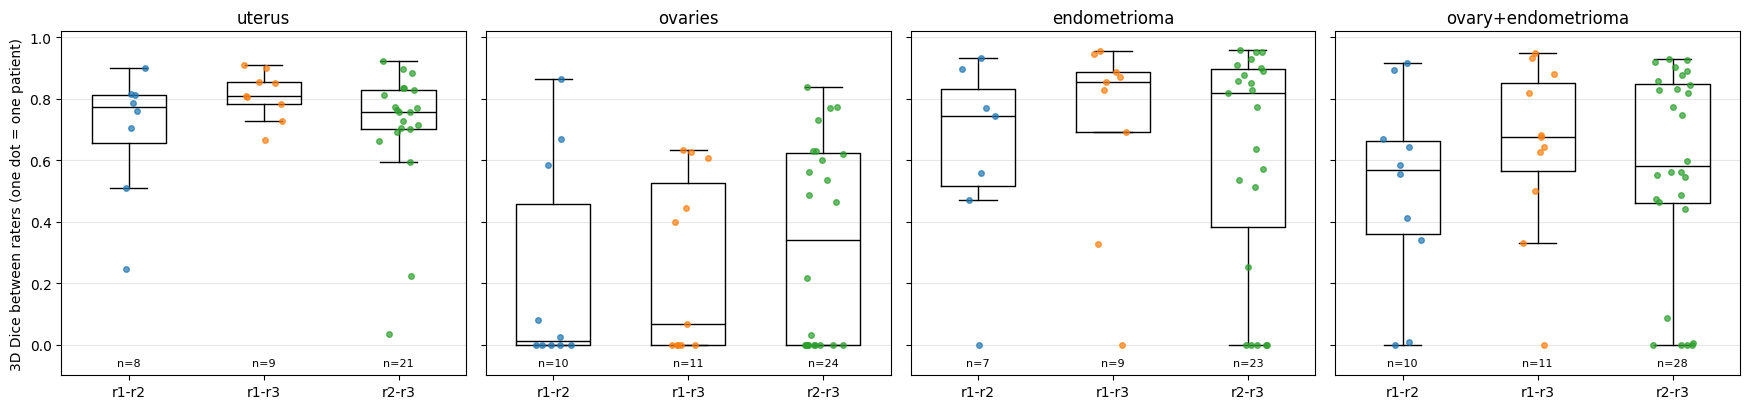

saved /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/rater_agreement_pairwise/fig_pairwise_dice.png

all outputs saved to: /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/rater_agreement_pairwise


In [ ]:
"""
Inter-rater agreement, PAIRWISE and availability-aware (replaces the all-three-raters Part 1).

Missing files are handled like this:
  * UTERUS: every patient has one, so a missing uterus file means "not annotated" -> that rater is
    Eexcluded for that patient (no Dice of 0, no volume of 0 mL).
  * OVARIES / ENDOMETRIOMA: a missing file can mean "none found", so for patients a rater annotated
    it counts as an empty mask.
"""
import os
import re
import glob
import itertools
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy.stats import friedmanchisquare, wilcoxon

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
FOLDER_NAME = "new results"          # outputs go to <folder>/rater_agreement_pairwise
MIN_PATIENTS_FOR_TESTS = 5
# -------------------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")


def find_folder(root, name, max_depth=3):
    root = root.rstrip("/")
    for dirpath, dirnames, _ in os.walk(root):
        if dirpath[len(root):].count(os.sep) >= max_depth:
            dirnames[:] = []
            continue
        for d in dirnames:
            if d.lower() == name.lower():
                return os.path.join(dirpath, d)
    return None


PROJECT_DIR = os.path.join(DRIVE_ROOT, FOLDER_NAME)
if not os.path.isdir(PROJECT_DIR):
    PROJECT_DIR = find_folder(DRIVE_ROOT, FOLDER_NAME)
if PROJECT_DIR is None:
    raise FileNotFoundError(f"No folder named '{FOLDER_NAME}' found under {DRIVE_ROOT}.")
OUT_DIR = os.path.join(PROJECT_DIR, "rater_agreement_pairwise")
os.makedirs(OUT_DIR, exist_ok=True)

CLASS_IDS = list(range(1, NUM_CLASSES))
WHOLE = "ovary+endometrioma"
ABBR = {LABEL_MAP[cid]: st for st, cid in STRUCTURES_OF_INTEREST.items()}   # 'uterus' -> 'ut'
_RATER_RE = re.compile(r"_(?P<st>[a-z]+)_(?P<rater>r\d+)\.nii\.gz$")


def case_rater_files(case):
    pdir = os.path.join(case["site_dir"], case["case_id"])
    out = {}
    for st in STRUCTURES_OF_INTEREST:
        for p in glob.glob(os.path.join(pdir, f"{case['case_id']}_{st}_r*.nii.gz")):
            m = _RATER_RE.search(os.path.basename(p))
            if m and m.group("st") == st:
                out.setdefault(m.group("rater"), {})[st] = p
    return out


def rater_label_paths(rater_files, rater):
    return {st: rater_files.get(rater, {}).get(st) for st in STRUCTURES_OF_INTEREST}


def volumetric_dice(a, b):
    denom = a.sum() + b.sum()
    return np.nan if denom == 0 else 2.0 * np.logical_and(a, b).sum() / denom


def icc_2_1(X):
    n, k = X.shape
    gm = X.mean()
    ss_r = k * ((X.mean(1) - gm) ** 2).sum()
    ss_c = n * ((X.mean(0) - gm) ** 2).sum()
    ss_e = ((X - gm) ** 2).sum() - ss_r - ss_c
    msr, msc, mse = ss_r / (n - 1), ss_c / (k - 1), ss_e / ((n - 1) * (k - 1))
    d = msr + (k - 1) * mse + k * (msc - mse) / n
    return (msr - mse) / d if d > 0 else np.nan


def holm(p):
    p = np.asarray(p, float)
    out, prev = np.full(len(p), np.nan), 0.0
    idx = np.where(~np.isnan(p))[0]
    for rank, i in enumerate(idx[np.argsort(p[idx])]):
        prev = max(prev, (len(idx) - rank) * p[i])
        out[i] = min(1.0, prev)
    return out


def participates(files, rater, organ):
    if rater not in files:
        return False                                   # rater did not annotate the patient at all
    if organ == "uterus":
        return "ut" in files[rater]                    # uterus: missing file = not annotated
    return True                                        # lesions/ovaries: missing file = none found


def collect(cases):
    files_all = {c["case_id"]: case_rater_files(c) for c in cases}
    raters = sorted({r for f in files_all.values() for r in f})
    pair_rows, vol_rows = [], []
    for c in cases:
        cid, files = c["case_id"], files_all[c["case_id"]]
        if len(files) < 2:
            continue
        image_nii = nib.as_closest_canonical(nib.load(c["image_path"]))
        vox_ml = float(np.prod(np.sqrt((image_nii.affine[:3, :3] ** 2).sum(0)))) / 1000.0
        masks = {r: load_combined_mask(image_nii, rater_label_paths(files, r)) for r in files}
        for cls in CLASS_IDS:
            organ = LABEL_MAP[cls]
            have = [r for r in sorted(files) if participates(files, r, organ)]
            for r in have:
                vol_rows.append({"case_id": cid, "organ": organ, "rater": r,
                                 "volume_ml": float((masks[r] == cls).sum()) * vox_ml})
            for ra, rb in itertools.combinations(have, 2):
                pair_rows.append({"case_id": cid, "organ": organ, "pair": f"{ra}-{rb}",
                                  "dice": volumetric_dice(masks[ra] == cls, masks[rb] == cls)})
        # whole ovary = ovary OR endometrioma: if this agrees much better than "ovaries" alone, raters
        # disagree about the label hierarchy (is the lesion part of the ovary?), not about location
        ov, em = STRUCTURES_OF_INTEREST["ov"], STRUCTURES_OF_INTEREST["em"]
        whole = {r: (masks[r] == ov) | (masks[r] == em) for r in files}
        for r in sorted(files):
            vol_rows.append({"case_id": cid, "organ": WHOLE, "rater": r,
                             "volume_ml": float(whole[r].sum()) * vox_ml})
        for ra, rb in itertools.combinations(sorted(files), 2):
            pair_rows.append({"case_id": cid, "organ": WHOLE, "pair": f"{ra}-{rb}",
                              "dice": volumetric_dice(whole[ra], whole[rb])})
    return raters, pd.DataFrame(pair_rows), pd.DataFrame(vol_rows)


def run_pairwise_agreement():
    cases = discover_cases(SITE_A_DIR)
    raters, pair_df, vol_df = collect(cases)
    pair_df.to_csv(os.path.join(OUT_DIR, "pairwise_dice.csv"), index=False)
    vol_df.to_csv(os.path.join(OUT_DIR, "volumes.csv"), index=False)
    organs = [LABEL_MAP[c] for c in CLASS_IDS] + [WHOLE]
    pairs = [f"{a}-{b}" for a, b in itertools.combinations(raters, 2)]

    print(f"raters: {raters}")
    print("\n=== Pairwise 3D Dice (mean / std / median / n patients with a value) ===")
    t = pair_df.groupby(["organ", "pair"])["dice"].agg(["mean", "std", "median", "count"]).round(3)
    print(t)
    t.to_csv(os.path.join(OUT_DIR, "table_pairwise_dice.csv"))

    print("\n=== Mean volume (mL) per rater, over patients where that rater has the organ ===")
    print(vol_df.pivot_table(index="organ", columns="rater", values="volume_ml",
                             aggfunc=["mean", "count"]).round(1))

    print("\n=== Do two raters label systematically different volumes? (paired, patients both annotated) ===")
    rows = []
    for organ in organs:
        w = vol_df[vol_df.organ == organ].pivot(index="case_id", columns="rater", values="volume_ml")
        ps, labs = [], []
        for ra, rb in itertools.combinations(raters, 2):
            both = w[[ra, rb]].dropna()
            both = both[(both > 0).any(axis=1)]                    # drop patients where both are empty
            if len(both) < MIN_PATIENTS_FOR_TESTS:
                rows.append({"organ": organ, "pair": f"{ra}-{rb}", "n": len(both)}); continue
            d = both[ra] - both[rb]
            p = wilcoxon(d).pvalue if (d != 0).any() else np.nan
            rows.append({"organ": organ, "pair": f"{ra}-{rb}", "n": len(both),
                         "mean_diff_ml": d.mean(), "p": p, "icc_2_1": icc_2_1(both.values)})
        part = [r for r in rows if r["organ"] == organ and "p" in r]
        for r, a in zip(part, holm([r["p"] for r in part])):
            r["p_holm"] = a
        allthree = w.dropna()
        allthree = allthree[(allthree > 0).any(axis=1)]
        if (len(raters) >= 3 and len(allthree) >= MIN_PATIENTS_FOR_TESTS
                and not np.allclose(allthree.values, allthree.values[:, [0]])):
            fp = friedmanchisquare(*[allthree[r].values for r in raters]).pvalue
            print(f"  {organ}: Friedman across all raters p={fp:.3f} (n={len(allthree)} patients all three have it)")
    tv = pd.DataFrame(rows)
    print(tv.round(3).to_string(index=False))
    tv.to_csv(os.path.join(OUT_DIR, "table_volume_tests.csv"), index=False)

    print("\n=== Same patients for every pair (only patients where ALL pairs have a value) ===")
    for organ in organs:
        w = (pair_df[pair_df.organ == organ].pivot(index="case_id", columns="pair", values="dice")
             .reindex(columns=pairs).dropna())
        if len(w):
            print(f"  {organ}: n={len(w)}   " + "   ".join(f"{pr} {w[pr].mean():.3f}" for pr in pairs))
    print("\n=== Lowest-agreement patients per organ: (patient, pair, Dice) ===")
    for organ in organs:
        low = pair_df[pair_df.organ == organ].dropna(subset=["dice"]).nsmallest(4, "dice")
        print(f"  {organ}: " + ", ".join(f"({r.case_id}, {r.pair}, {r.dice:.2f})" for r in low.itertuples()))
    print("\n=== Largest volume disagreements between two raters: (patient, pair, difference mL) ===")
    for organ in ["uterus", "endometrioma"]:
        w = vol_df[vol_df.organ == organ].pivot(index="case_id", columns="rater", values="volume_ml")
        recs = []
        for ra, rb in itertools.combinations(raters, 2):
            for cid, v in (w[ra] - w[rb]).dropna().items():
                recs.append((abs(v), cid, f"{ra}-{rb}", round(float(v), 1)))
        recs.sort(reverse=True)
        print(f"  {organ}: " + ", ".join(f"({c}, {pr}, {v:+})" for _, c, pr, v in recs[:4]))

    # figure: pairwise Dice per patient
    fig, axes = plt.subplots(1, len(organs), figsize=(4.4 * len(organs), 4.2), sharey=True)
    rng = np.random.RandomState(0)
    for ax, organ in zip(np.atleast_1d(axes), organs):
        for k, pr in enumerate(pairs):
            x = pair_df[(pair_df.organ == organ) & (pair_df.pair == pr)]["dice"].dropna().values
            if len(x):
                ax.boxplot(x, positions=[k], widths=.55, showfliers=False, medianprops=dict(color="k"))
                ax.scatter(k + rng.uniform(-.15, .15, len(x)), x, s=16, alpha=.7, zorder=3)
            ax.text(k, -0.07, f"n={len(x)}", ha="center", fontsize=8)
        ax.set_xticks(range(len(pairs))); ax.set_xticklabels(pairs); ax.set_ylim(-0.1, 1.02)
        ax.set_title(organ); ax.grid(axis="y", alpha=.3)
    np.atleast_1d(axes)[0].set_ylabel("3D Dice between raters (one dot = one patient)")
    fig.tight_layout()
    out = os.path.join(OUT_DIR, "fig_pairwise_dice.png")
    fig.savefig(out, dpi=140); plt.show(); print("saved", out)
    print("\nall outputs saved to:", OUT_DIR)
    return pair_df, vol_df


df_pair, df_vol = run_pairwise_agreement()